**Informe: Análisis Exploratorio y Fundamentos Metodológicos para un Modelo de Reconocimiento de Lenguaje de Signos**

# 1. Introducción y Objetivos
Las barreras de comunicación entre las comunidades sordas y oyentes representan un desafío social y tecnológico persistente. Las tecnologías emergentes, específicamente la Visión por Computador y el Deep Learning, ofrecen una oportunidad sin precedentes para desarrollar herramientas de traducción automática que faciliten la accesibilidad universal.

Este proyecto se inscribe en este contexto, con la finalidad de desarrollar un componente fundamental para dichos sistemas: un modelo de clasificación de imágenes estáticas del lenguaje de señas que sea preciso, robusto y eficiente. El desafío no es trivial, ya que implica la captura de matices gestuales complejos en una simple imagen fija.

Objetivo Principal

El objetivo principal de esta investigación es el desarrollo y la evaluación de un modelo de Red Neuronal Convolucional (CNN) capaz de alcanzar una precisión de clasificación superior al 95% en un dataset de imágenes estáticas.

Objetivos Secundarios

Para alcanzar esta meta, se plantean los siguientes objetivos secundarios, diseñados para validar la calidad y viabilidad del modelo más allá de una simple métrica de precisión:

Identificar y Analizar los Patrones de Error: Investigar la naturaleza de los fallos de clasificación del modelo. El objetivo es determinar si existen patrones sistemáticos en los errores, como la confusión recurrente entre pares o grupos de señas específicas, para diagnosticar las limitaciones del modelo.

Evaluar la Robustez ante Entornos No Ideales: Medir la capacidad de generalización del modelo más allá de las condiciones "limpias" del dataset. Se evaluará la degradación del rendimiento al introducir perturbaciones controladas en las imágenes de validación (p.ej., ruido gaussiano, variaciones de iluminación, pequeñas rotaciones) que simulen imperfecciones del mundo real.

Optimizar la Eficiencia del Modelo: Determinar la arquitectura de CNN más eficiente (en términos de parámetros y coste computacional) que logre cumplir con el objetivo de precisión principal, asegurando que la solución sea potencialmente desplegable en aplicaciones prácticas.





# 2. Estado del arte

El reconocimiento del lenguaje de señas (Sign Language Recognition, SLR) es un área de investigación activa dentro de la Visión por Computador. Históricamente, los enfoques se basaban en la extracción manual de características y clasificadores tradicionales. Sin embargo, la revolución del Deep Learning ha redefinido el campo, sustituyendo estos métodos por arquitecturas de aprendizaje profundo de extremo a extremo (Krizhevsky et al., 2012).

Este proyecto se enfoca en el Reconocimiento de Señas Aisladas Estáticas, un subcampo que, aunque no captura la dinámica temporal del lenguaje, es un primer paso fundamental para la traducción y sirve como un benchmark robusto para la clasificación de grano fino.

1. Desafíos Fundamentales

La literatura identifica de forma consistente desafíos que van más allá de un simple problema de clasificación de imágenes:


*   Alta Similitud Inter-clase y Variabilidad Intra-clase: Es el desafío dominante. Muchas señas (clases) son visualmente casi idénticas, diferenciándose solo por la orientación de un pulgar. Al mismo tiempo, la forma en que diferentes individuos ejecutan la misma seña (variabilidad intra-clase) puede ser drásticamente diferente (Koller et al., 2016).

*   Robustez al Entorno: Los modelos entrenados en condiciones de laboratorio (fondos uniformes, iluminación perfecta) fallan estrepitosamente en entornos reales. Los factores clave son los fondos complejos (que pueden contener "falsos positivos" de manos) y las variaciones de iluminación (que alteran la percepción de la forma y los bordes) (Rao, 2021).



*   La "Maldición" de la Imagen Estática: A diferencia del vídeo, una imagen estática carece de contexto temporal (movimiento), que es un componente fonológico clave en el lenguaje de señas. Esto obliga al modelo a depender exclusivamente de la morfología de la mano, aumentando la dificultad.


2. Enfoques Arquitectónicos y Pre-procesamiento

Para abordar estos retos, el estado del arte ha convergido en varias estrategias metodológicas:

Transfer Learning (Aprendizaje por Transferencia): Es la práctica estándar. En lugar de entrenar una Red Neuronal Convolucional (CNN) desde cero, se utiliza un modelo (p.ej., VGG16, ResNet-50, EfficientNet) pre-entrenado en un dataset masivo como ImageNet. Estas redes ya actúan como potentes extractores de características visuales (bordes, texturas). El trabajo de SLR consiste en "sintonizar" (fine-tuning) estas redes para la tarea específica de clasificar señas (Pigou et al., 2018).

**Manejo de la Región de Interés** (ROI): El debate en la literatura no es si la mano es importante, sino cómo indicárselo al modelo:


*   Segmentación Explícita: El enfoque tradicional. Utiliza algoritmos (desde segmentación por color de piel hasta modelos de DL como U-Net) para recortar la mano del fondo.

Ventaja: Reduce el ruido y fuerza al modelo a centrarse en la ROI.

Desventaja: Es un punto de fallo. Falla con diferentes tonos de piel, fondos complejos o si hay dos personas en la escena (Neethu & Anilkumar, 2019).

*   Atención Implícita (End-to-End): El enfoque moderno. Se entrega la imagen completa a una arquitectura de CNN que contenga mecanismos de atención (p.ej., Squeeze-and-Excitation, o los inherentes a los Vision Transformers). El modelo aprende por sí mismo a "prestar más atención" a los píxeles relevantes (la mano) e ignorar el fondo (Vaswani et al., 2017; Hu et al., 2018).





**Aumentación de Datos** (Data Augmentation): Sigue siendo fundamental para la generalización y la robustez. Más allá de las transformaciones geométricas básicas (rotación, zoom, traslación), para el SLR son cruciales las técnicas que simulan desafíos reales:


*   Aumentación Fotométrica: Variaciones de brillo, contraste y saturación (simulan cambios de luz).

*   Ruido: Adición de ruido gaussiano o "sal y pimienta" (simulan sensores de baja calidad).

*   Recortes Aleatorios (Random Erasing/Cutout): Se eliminan parches aleatorios de la imagen. Esto fuerza al modelo a no depender de una única característica (como la punta de un dedo) y a ver la "gestalt" de la mano (DeVries & Taylor, 2017).





Este proyecto se posiciona en este contexto, buscando evaluar una arquitectura CNN moderna, optimizada mediante transfer learning y robustecida con un protocolo de aumentación de datos, para superar la barrera del 95% de precisión en un entorno estático.

# 3. Metodología

La metodología empleada en este trabajo está alineada con el proceso de Descubrimiento de Conocimiento en Bases de Datos (KDD) y el estándar CRISP-DM. La **Figura 1** detalla las etapas seguidas para alcanzar los objetivos de la investigación, desde la adquisición de los datos hasta la interpretación del conocimiento.

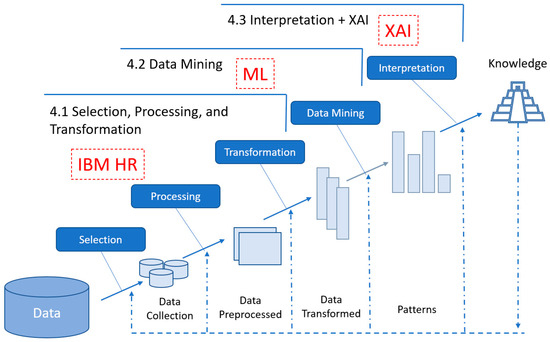


Figura 1. Flujo metodológico de la investigación (Marín Díaz et al., 2023)

Los datos utilizados en este estudio corresponden al dataset público "Sign Language Detection using Images". A continuación, se detalla el desarrollo de cada etapa del modelo.

3.1. Selección, Procesamiento y Transformación (Fase 4.1) (ACTUAL)

Esta etapa inicial se centra en la preparación de los datos.

1. Procesamiento (Preprocessing): Se realizará un Análisis Exploratorio de Datos (EDA) para auditar la calidad del dataset. Esto incluye la verificación del balance de clases, la consistencia dimensional de las imágenes y el análisis de ruido mediante histogramas de píxeles.

2. Transformación (Transformation): Basado en los desafíos del estado del arte, se planifican dos transformaciones: (1) Recorte (Cropping) a la Región de Interés (ROI) para optimizar el modelo y (2) Aumentación de Datos (incluyendo ruido gaussiano) para asegurar la robustez.

3.2. Data Mining (Fase 4.2 - ML) (SIGUIENTE FASE)

Esta fase aplicará algoritmos de Machine Learning para alcanzar el objetivo predictivo.

1. Algoritmo y Métrica: Se entrenará una Red Neuronal Convolucional (CNN) y se medirá su rendimiento con la métrica de Accuracy, aspirando a superar el 95%.

2. Análisis de Error: Se generará una Matriz de Confusión detallada para validar la hipótesis sobre la ambigüedad entre clases (ej. 'A' vs 'S').

3.3. Interpretación + XAI (Fase 4.3) (FASE FUTURA)

Dado que las CNNs son modelos "caja negra", se aplicarán técnicas de Interpretabilidad (XAI) para generar conocimiento.

1. Análisis Global: Se usarán técnicas como t-SNE y SHAP para entender el comportamiento general del modelo y la importancia de las características.

2. Análisis Local: Para evaluar la gestión de la ambigüedad, se analizará el vector de salida softmax (probabilidades), aplicando un enfoque de "Grado de Pertenencia" (Lógica Difusa) a las predicciones en clases ambiguas.



# 4. Desarrollo

Comenzamos con la fase del EDA


Imports

In [ ]:
import numpy as np
import pandas as pd
import os
import cv2
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
import keras
from tqdm import tqdm
from tensorflow.keras.preprocessing import image
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping ,ReduceLROnPlateau
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.models import Model, Sequential
from tensorflow.keras.layers import Input, Average, Dropout, Dense, Flatten, Concatenate
from tensorflow.keras.applications import VGG16, InceptionV3, MobileNetV2
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.utils.class_weight import compute_class_weight
import glob
import pandas as pan
import matplotlib.pyplot as plotter
import warnings
import kagglehub
from pathlib import Path
warnings.filterwarnings('ignore')

Cargar Dataset

In [ ]:

path_str = kagglehub.dataset_download("harshvardhan21/sign-language-detection-using-images")

data_dir = Path(path_str) / 'data'

class_folders = os.listdir(data_dir)# devuelve una lista con los nombres de todos los archivos y carpetas que se encuentran dentro del directorio especificado en la variable data_dir.

df = pd.DataFrame(class_folders, columns=['Nombre_Carpeta_Clase'])

print(df)


Using Colab cache for faster access to the 'sign-language-detection-using-images' dataset.
   Nombre_Carpeta_Clase
0                     N
1                     7
2                     R
3                     2
4                     B
5                     I
6                     F
7                     H
8                     5
9                     E
10                    U
11                    M
12                    8
13                    X
14                    K
15                    Q
16                    Y
17                    S
18                    G
19                    A
20                    O
21                    T
22                    V
23                    Z
24                    3
25                    1
26                    C
27                    4
28                    P
29                    9
30                    L
31                    6
32                    W
33                    D
34                    J


Ya tengo el dataset, ahora quiero organizarlo de manera que estén primeros las fotos de los números de menor a mayor y luego las fotos de las letras siguiendo un orden alfabético

In [ ]:
numeros = []
letras = []

for item in class_folders:
    if item.isdigit():
        numeros.append(item)
    else:
        letras.append(item)

numeros_ordenados = sorted(numeros, key=int)

letras_ordenadas = sorted(letras)

lista_ordenada_final = numeros_ordenados + letras_ordenadas


print(list(enumerate(lista_ordenada_final)))
df_ordenado = pd.DataFrame(lista_ordenada_final, columns=['Nombre_Carpeta_Clase'])


print("\nDataFrame ordenado:")
print(df_ordenado)

df = df_ordenado


DataFrame ordenado:
   Nombre_Carpeta_Clase
0                     1
1                     2
2                     3
3                     4
4                     5
5                     6
6                     7
7                     8
8                     9
9                     A
10                    B
11                    C
12                    D
13                    E
14                    F
15                    G
16                    H
17                    I
18                    J
19                    K
20                    L
21                    M
22                    N
23                    O
24                    P
25                    Q
26                    R
27                    S
28                    T
29                    U
30                    V
31                    W
32                    X
33                    Y
34                    Z


Dando un primer vistazo, nos damos cuenta que no hay fotos de la Ñ por lo tanto este dataset no serviría para todas las palabras del español, además no hay imágenes del 0.

Una idea de expansión sería recopilar diferentes imágenes de Ñ y de 0 para poder tener el dataset completo.

In [ ]:
conteo_imgs = {}
imgs_totales = 0


nombre_clases = df['Nombre_Carpeta_Clase'].tolist()


for class_name in nombre_clases:
    class_dir = data_dir / class_name

    count = len(list(class_dir.glob('*.*')))
    conteo_imgs[class_name] = count
    imgs_totales += count

print(f"Número total de clases: {len(nombre_clases)}")
print(f"Número total de imágenes: {imgs_totales}")



Número total de clases: 35
Número total de imágenes: 42000


Hay un total de 35 imagenes y 42000 imágenes

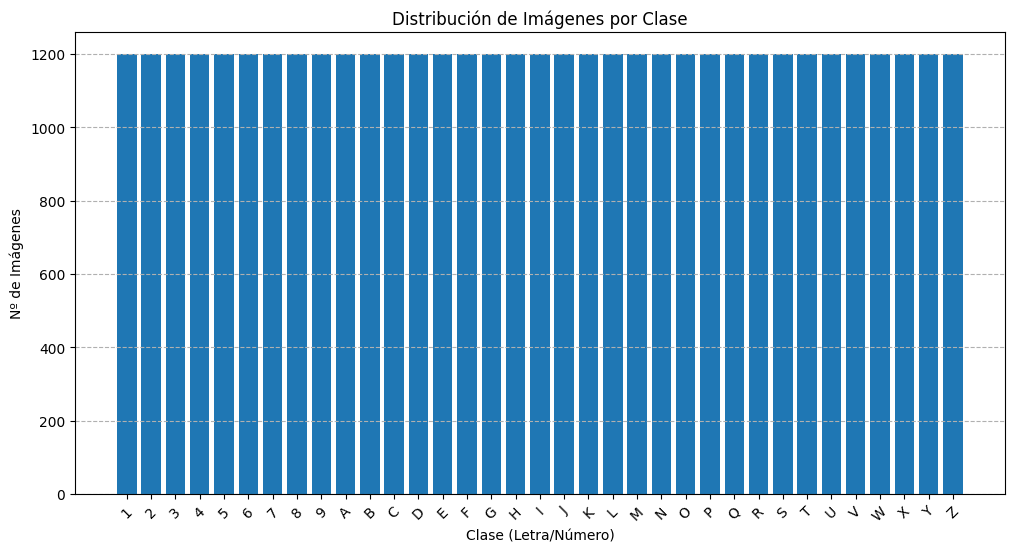

In [ ]:
plt.figure(figsize=(12, 6))
plt.bar(conteo_imgs.keys(), conteo_imgs.values())
plt.title('Distribución de Imágenes por Clase')
plt.xlabel('Clase (Letra/Número)')
plt.ylabel('Nº de Imágenes')
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--')
plt.show()

In [ ]:
from tqdm import tqdm # Importamos tqdm para la barra de progreso

print("Verificando la consistencia dimensional de las imágenes...")

image_dimensions = []

# Recorremos cada clase (carpeta)
# Asegúrate de que 'lista_ordenada_final' y 'data_dir' están definidos y ejecutados en celdas anteriores
for class_name in tqdm(lista_ordenada_final, desc="Procesando clases para dimensiones"):
    class_path = data_dir / class_name

    # Recorremos cada imagen dentro de la clase
    for img_file in os.listdir(class_path):
        img_path = str(class_path / img_file)
        image = cv2.imread(img_path)

        if image is not None:
            # Guardamos las dimensiones (altura, anchura)
            image_dimensions.append(image.shape[:2])
        else:
            print(f"Advertencia: No se pudo leer la imagen {img_path}")

# Convertimos la lista de dimensiones a un conjunto para encontrar dimensiones únicas
unique_dimensions = set(image_dimensions)

# Asegúrate de que 'imgs_totales' está definido y ejecutado en una celda anterior
if len(unique_dimensions) == 1:
    # Para imprimir las dimensiones, necesitamos una forma de acceder al único elemento del conjunto
    # Convertimos el conjunto a una lista para extraer el elemento
    single_dim = list(unique_dimensions)[0]
    print(f"\nTodas las {imgs_totales} imágenes tienen el mismo tamaño: {single_dim[0]}x{single_dim[1]}")
else:
    print("\n¡Advertencia! Las imágenes tienen diferentes tamaños. Deberías estandarizarlas.")
    print("Dimensiones encontradas:")
    for dim in unique_dimensions:
        print(f"- {dim[0]}x{dim[1]}")


Verificando la consistencia dimensional de las imágenes...


Procesando clases para dimensiones: 100%|██████████| 35/35 [04:18<00:00,  7.39s/it]


Todas las 42000 imágenes tienen el mismo tamaño: 128x128


Tras ver este gráfico podemos saber que no hay un desbalance de clases lo que hubiera sido un gran problema, todas las clases tienen el mismo número de imágenes.

Limpieza: No se requirió tratar valores nulos, ya que el dataset consiste en archivos de imagen. Se verificó que no hubiera archivos corruptos durante la carga.


Cargando una imagen de muestra por cada clase...


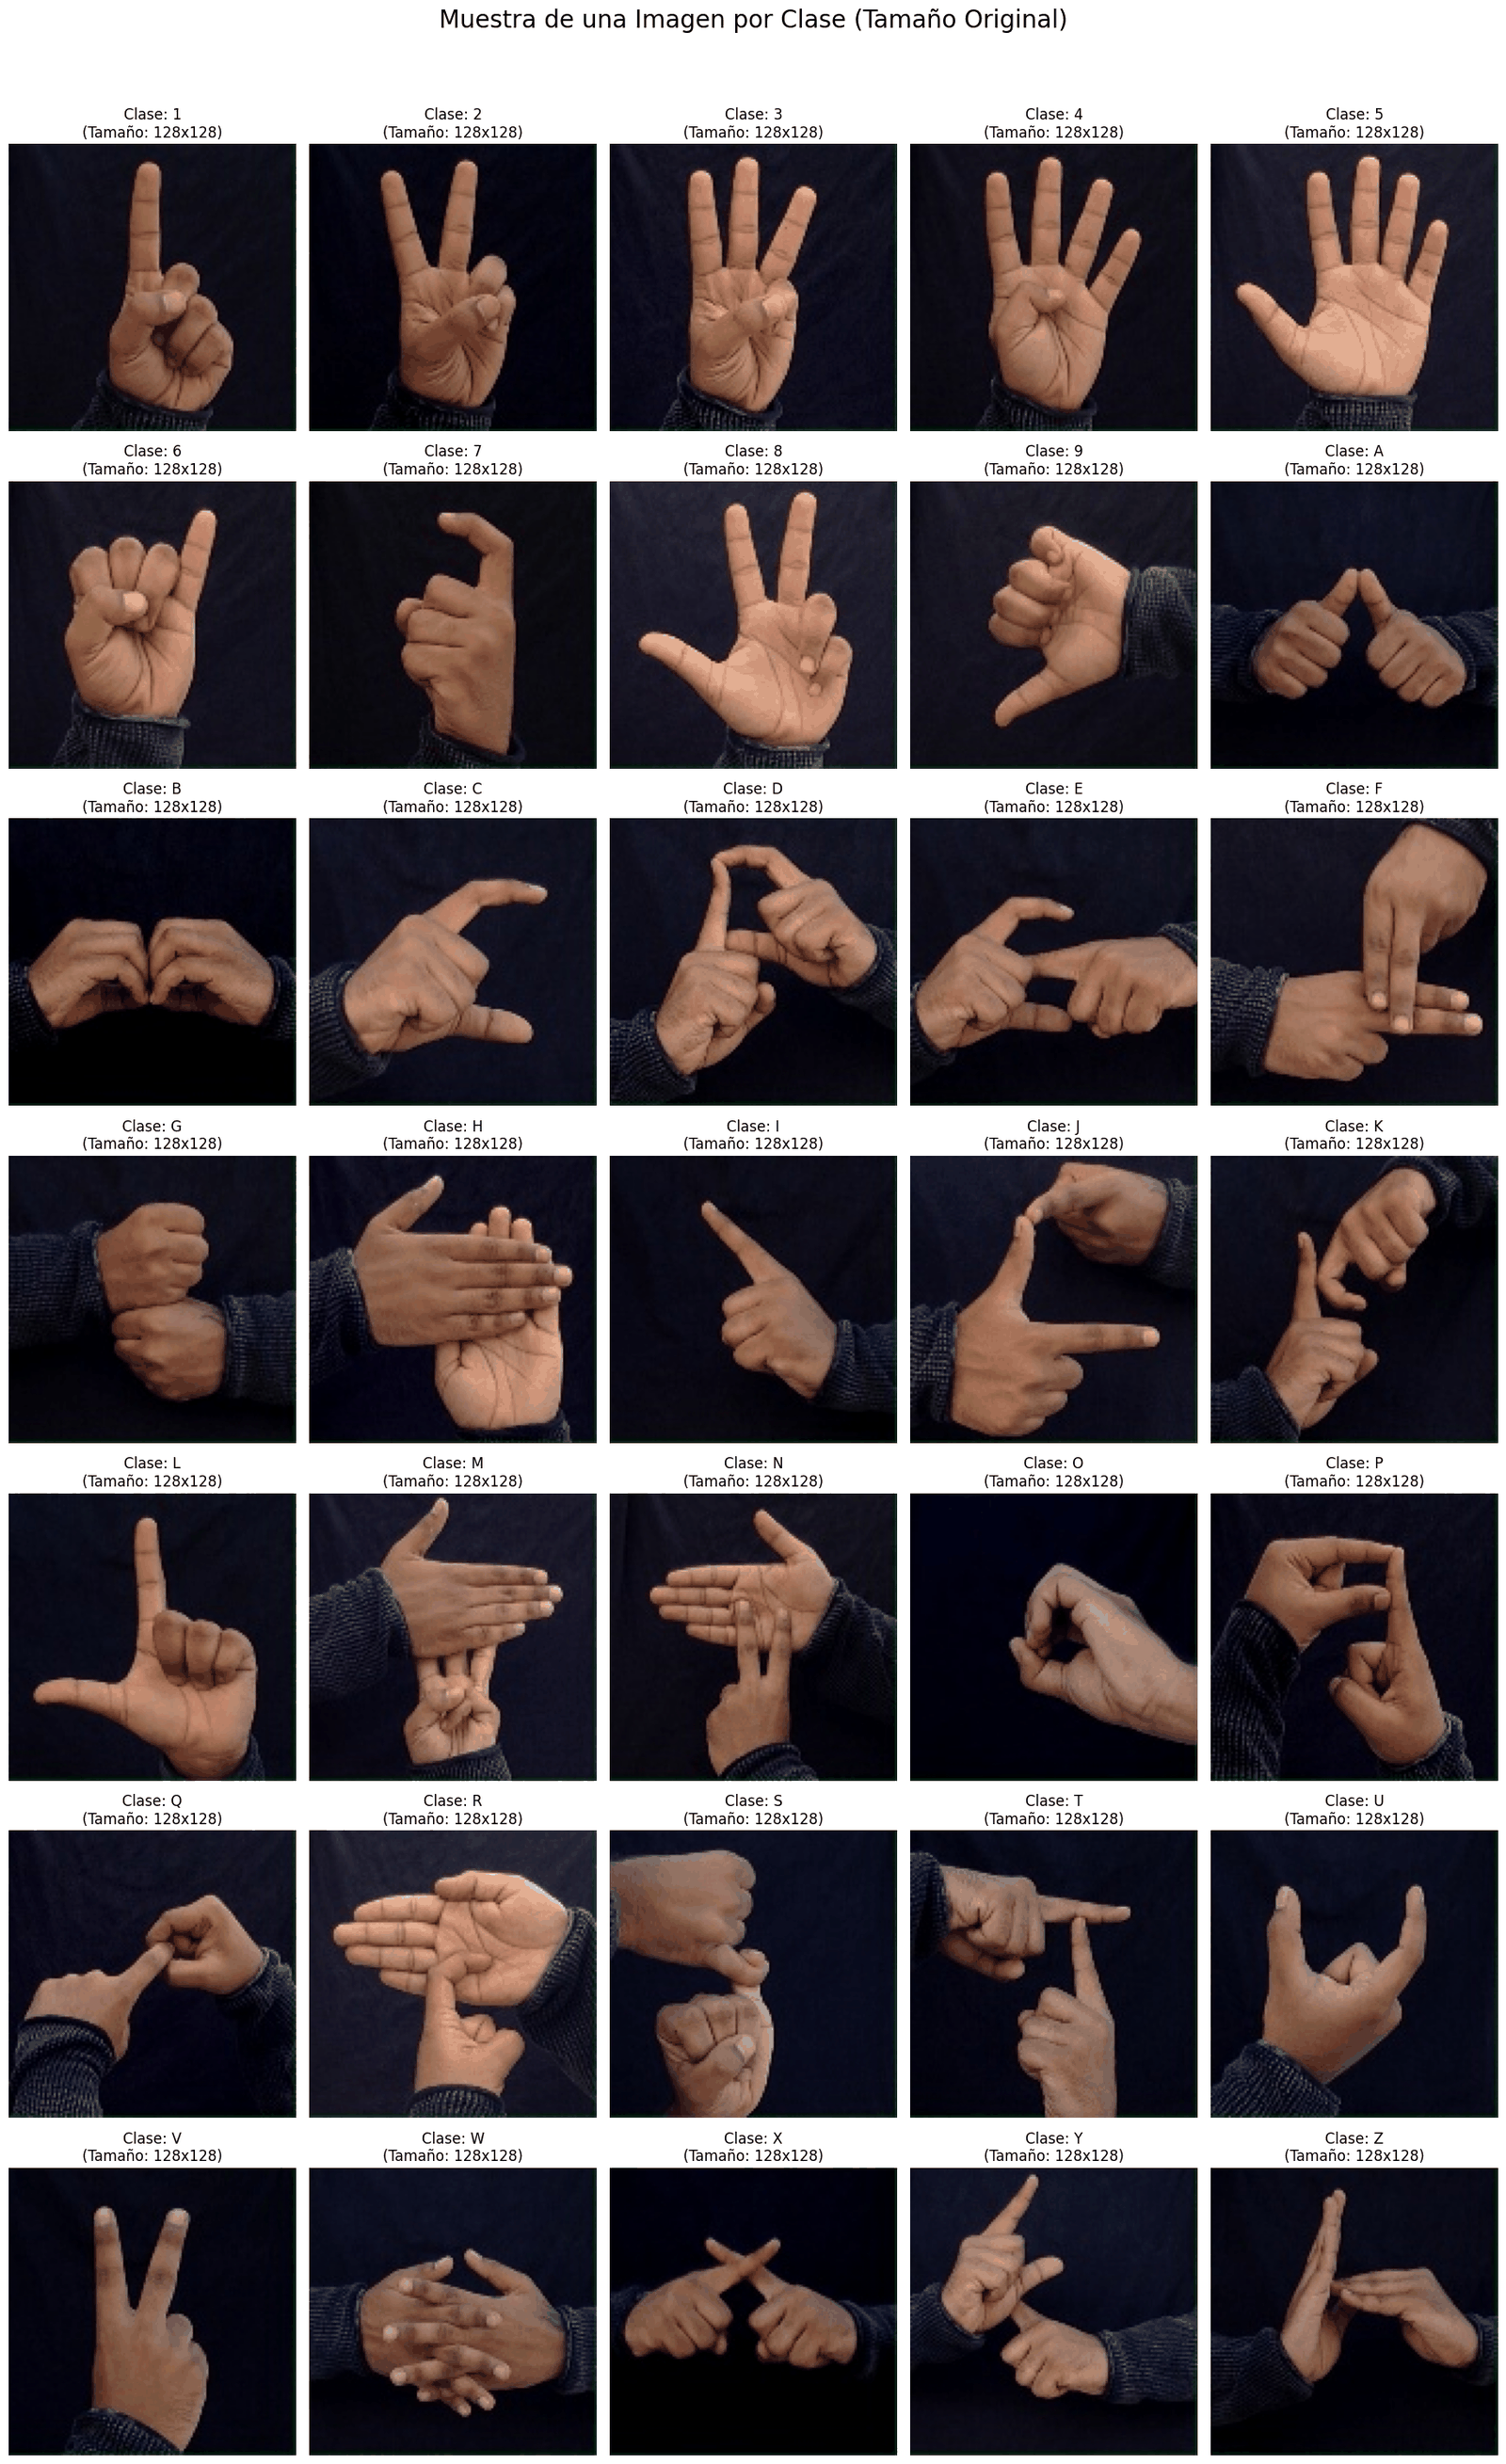

In [ ]:
num_classes = len(lista_ordenada_final)
rows = 7 # 7 filas
cols = 5 # 5 columnas (7x5 = 35 clases)

fig, axes = plt.subplots(rows, cols, figsize=(cols * 3.5, rows * 4)) # Ajustamos el tamaño

print("Cargando una imagen de muestra por cada clase...")

for i, class_name in enumerate(lista_ordenada_final):

    row = i // cols
    col = i % cols
    ax = axes[row, col]


    class_path = data_dir / class_name
    image_files = os.listdir(class_path)

    if image_files: # Nos aseguramos de que la carpeta no esté vacía

        img_path = str(class_path / image_files[0])

        # Leer la imagen con OpenCV (cv2)
        image = cv2.imread(img_path)

        #¡Importante! Convertir de BGR (OpenCV) a RGB (Matplotlib)
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

        # Mostrar la imagen
        ax.imshow(image)
        # Añadimos el tamaño (Alto, Ancho) al título
        ax.set_title(f"Clase: {class_name}\n(Tamaño: {image.shape[0]}x{image.shape[1]})")
        ax.axis('off')
    else:
        ax.set_title(f"Clase: {class_name}\n(Vacío)")
        ax.axis('off')

plt.suptitle("Muestra de una Imagen por Clase (Tamaño Original)", fontsize=20, y=1.02)
plt.tight_layout()
plt.show()

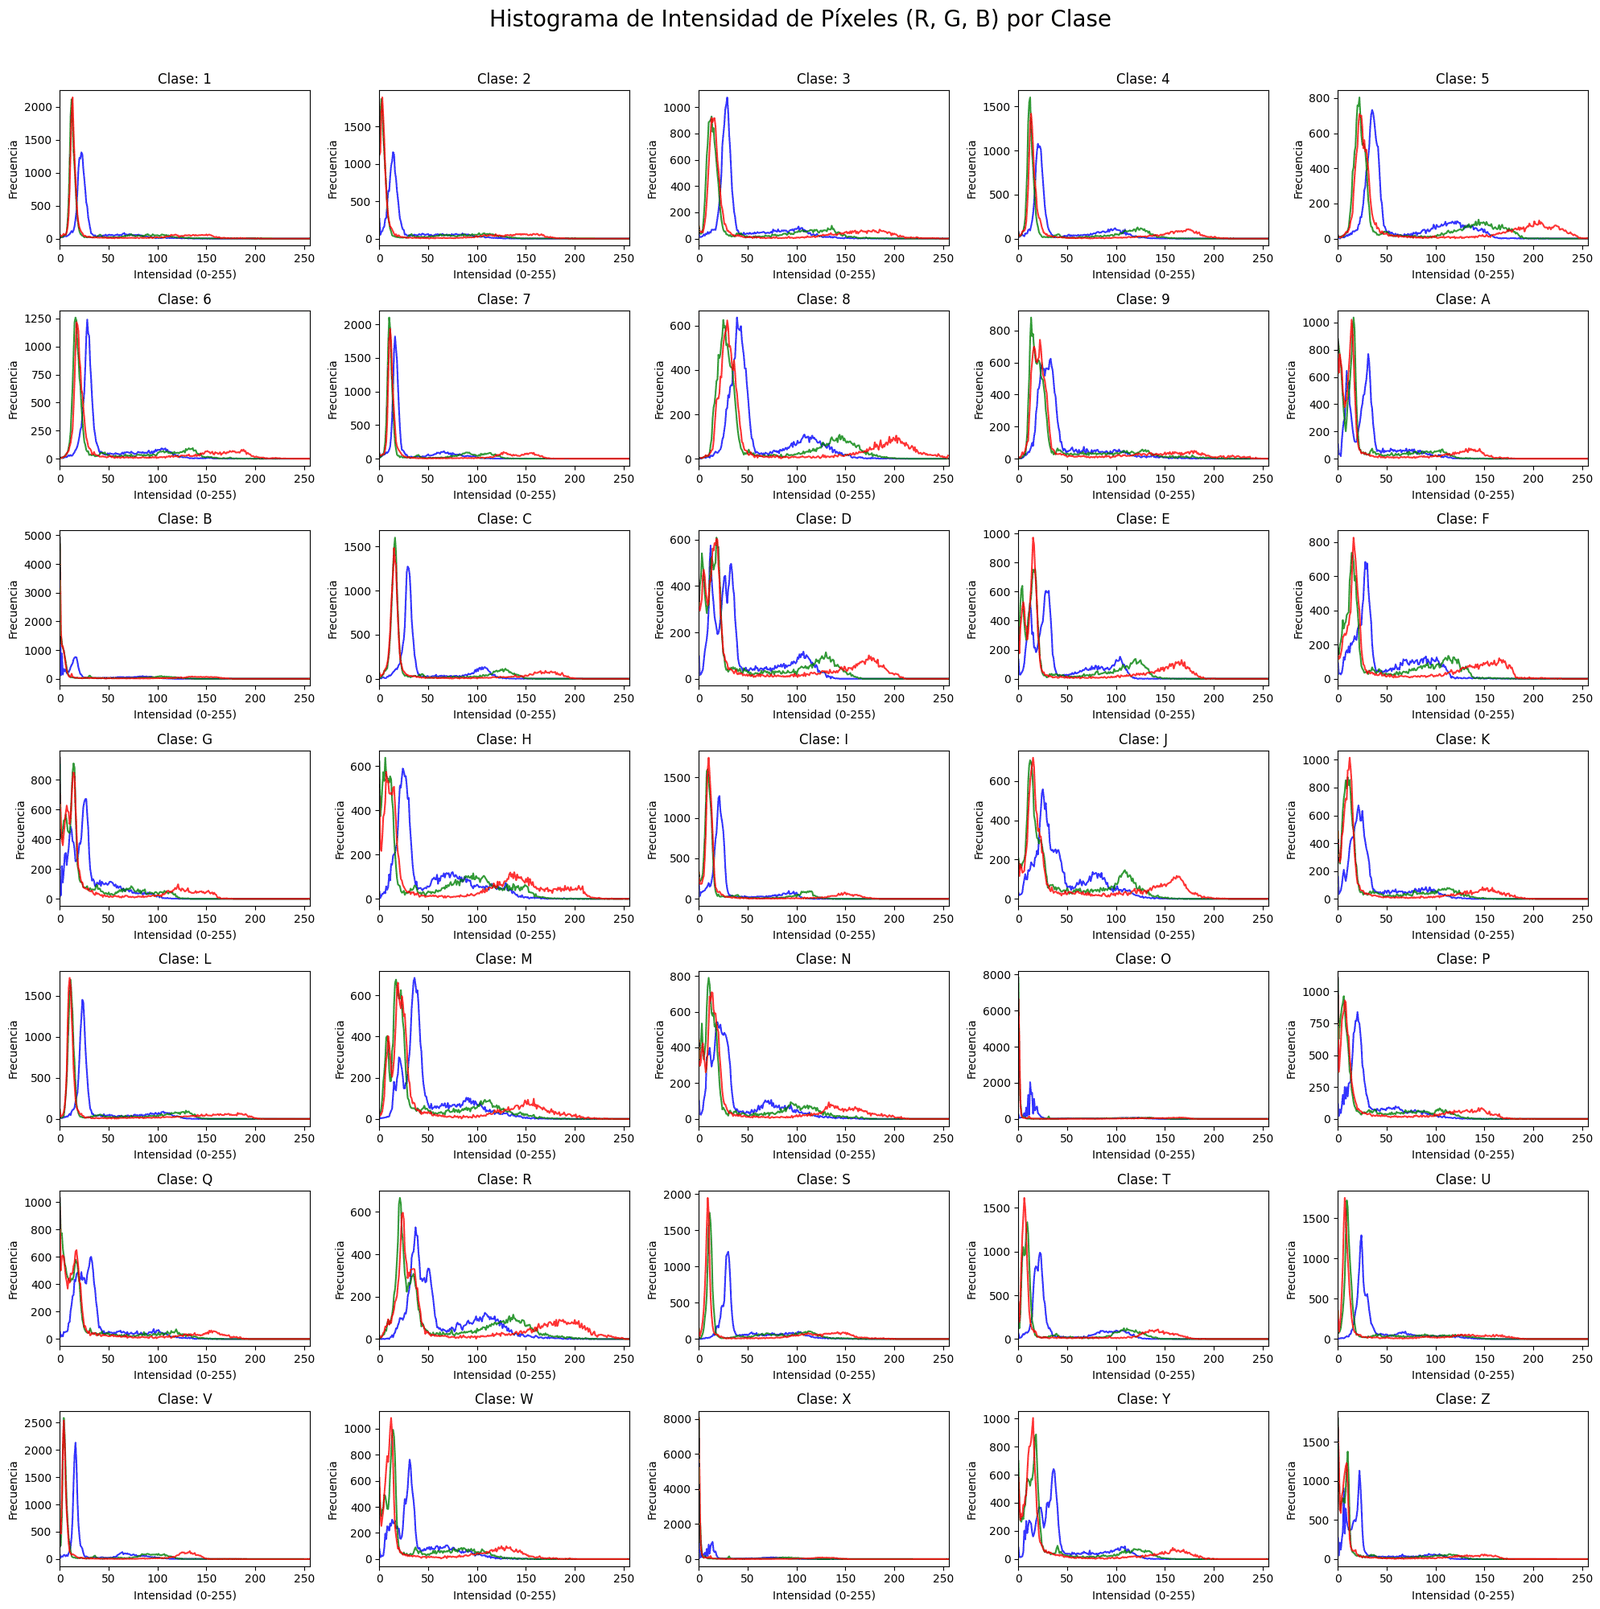

In [ ]:
# (Asumimos que 'data_dir' y 'lista_ordenada_final' están definidos)
# Usaremos 'lista_ordenada_final' en lugar de 'clases_ejemplo'

num_classes = len(lista_ordenada_final)
rows = 7 # 7 filas
cols = 5 # 5 columnas (7x5 = 35 clases)

plt.figure(figsize=(cols * 4, rows * 3)) # Ajustamos el tamaño de la figura
plt.suptitle("Histograma de Intensidad de Píxeles (R, G, B) por Clase", fontsize=20)

for i, class_name in enumerate(lista_ordenada_final):
    # 1. Cargar la primera imagen de la clase
    class_path = data_dir / class_name
    img_path = str(class_path / os.listdir(class_path)[0])
    image = cv2.imread(img_path)

    if image is None:
        print(f"Advertencia: No se pudo leer imagen para la clase {class_name}")
        continue

    # 2. Separar canales (B, G, R) - OpenCV lee como BGR
    colores = ('b', 'g', 'r')

    # 3. Calcular la posición en la cuadrícula
    ax = plt.subplot(rows, cols, i + 1)

    for canal, color in enumerate(colores):
        # 4. Calcular el histograma para el canal
        # 256 "bins" (uno para cada valor de 0 a 255)
        hist = cv2.calcHist([image], [canal], None, [256], [0, 256])
        plt.plot(hist, color=color, alpha=0.8)

    ax.set_title(f"Clase: {class_name}")
    ax.set_xlabel("Intensidad (0-255)")
    ax.set_ylabel("Frecuencia")
    ax.set_xlim([0, 256])

# Ajustar layout para que no se solapen
plt.tight_layout(rect=[0, 0.03, 1, 0.97])
plt.show()

Todos los 35 histogramas son casi idénticos en su estructura.

¿Qué significa? Que todas las 42.000 imágenes (1.200 por clase) se tomaron en condiciones de iluminación y fondo idénticas o casi idénticas. No hay variaciones de luz, ni sombras raras, ni fondos diferentes.

¿Por qué importa? Esto es importante para un modelo ya que no hay nada de ruido, las imágenes son "perfectas", esto puede llegar a ser un problema de overfitting ya que el modelo se aprenderia las fotos del dataset pero generalixaría mal en el mundo real (En imágenes diferentes a las del dataset).

Calculando imágenes promedio (Esto leerá las 42,000 imágenes, puede tardar)...


Calculando promedios: 100%|██████████| 35/35 [00:50<00:00,  1.46s/it]


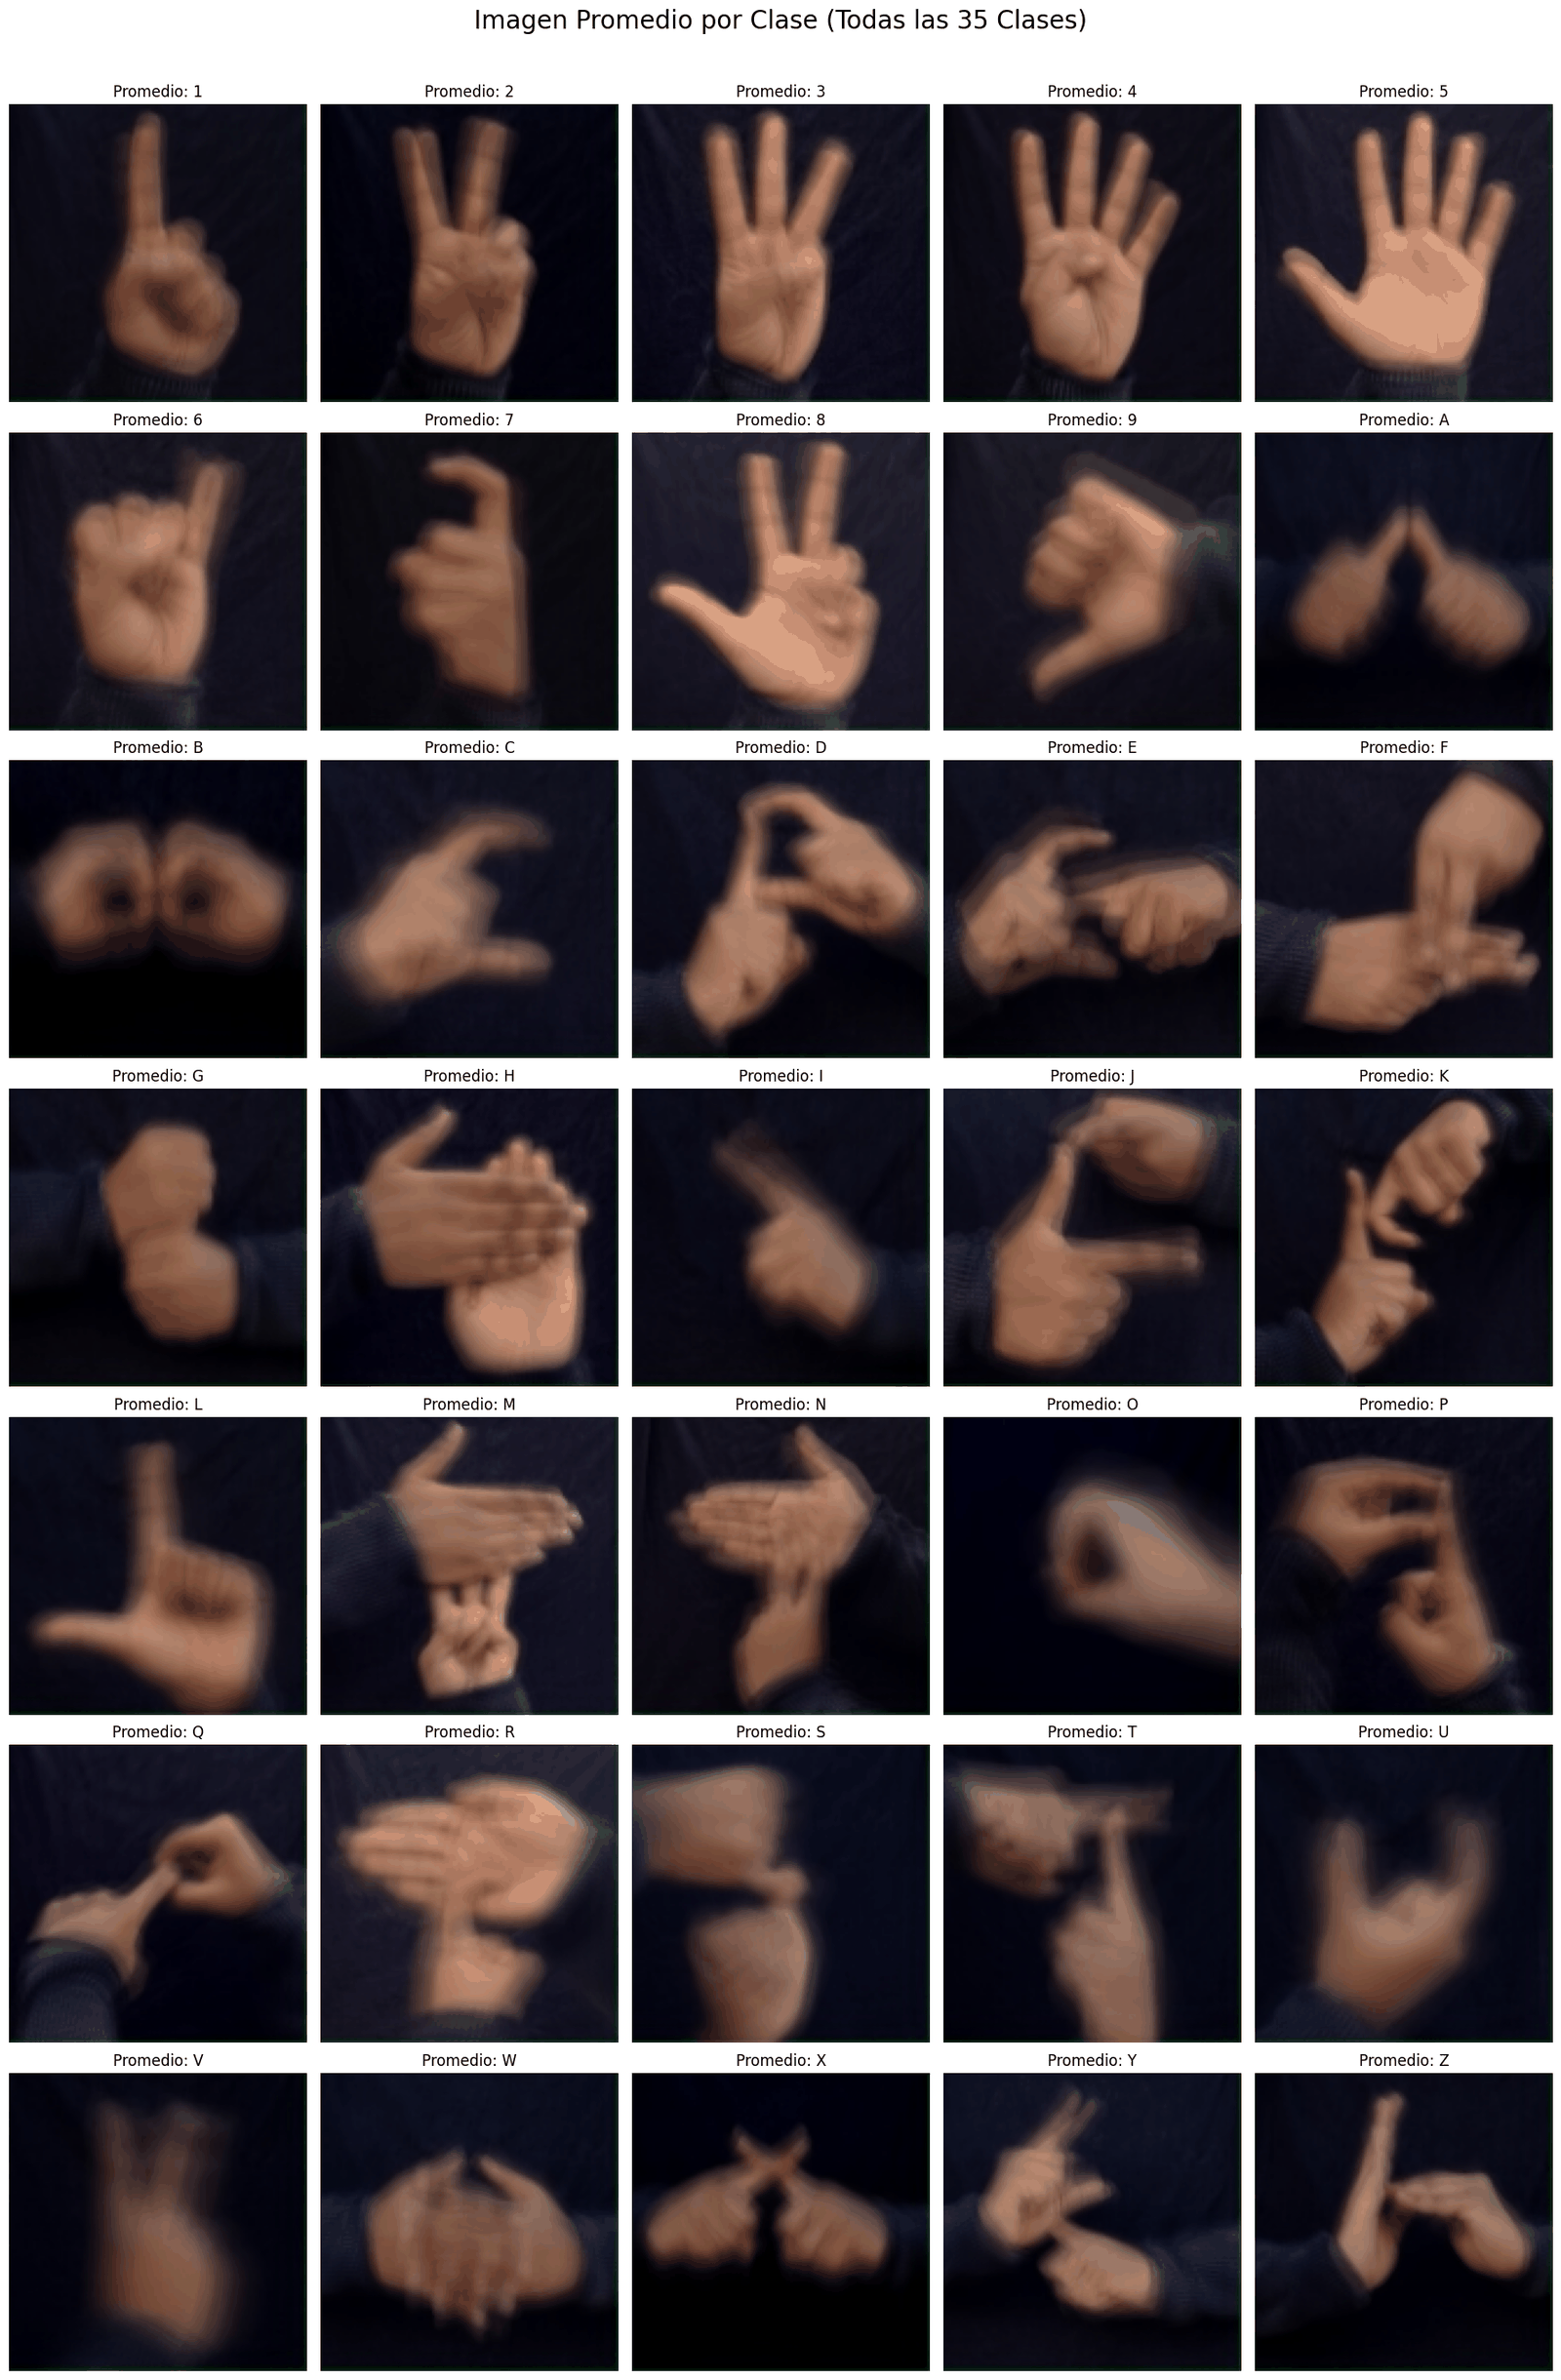

In [ ]:
from tqdm import tqdm # Asegúrate de que tqdm está importado

# (Asumimos 'data_dir' y 'lista_ordenada_final' están definidos)

num_classes = len(lista_ordenada_final)
rows = 7 # 7 filas
cols = 5 # 5 columnas (7x5 = 35 clases)

plt.figure(figsize=(cols * 3.5, rows * 4)) # Ajustamos el tamaño
plt.suptitle("Imagen Promedio por Clase (Todas las 35 Clases)", fontsize=20)

print("Calculando imágenes promedio (Esto leerá las 42,000 imágenes, puede tardar)...")

# 1. Usamos tqdm para ver el progreso
for i, class_name in enumerate(tqdm(lista_ordenada_final, desc="Calculando promedios")):
    class_path = data_dir / class_name
    imagenes_clase = []

    # 2. Cargar todas las imágenes de la clase
    for img_file in os.listdir(class_path):
        img = cv2.imread(str(class_path / img_file))
        if img is not None:
            imagenes_clase.append(img)

    # Nos aseguramos de que la carpeta no estaba vacía
    if imagenes_clase:
        # 3. Calcular el promedio (usando numpy)
        imagen_promedio = np.mean(imagenes_clase, axis=0).astype('uint8')

        # 4. Convertir a RGB y mostrar
        imagen_promedio_rgb = cv2.cvtColor(imagen_promedio, cv2.COLOR_BGR2RGB)

        # 5. Colocar en la cuadrícula 7x5
        ax = plt.subplot(rows, cols, i + 1)
        ax.imshow(imagen_promedio_rgb)
        ax.set_title(f"Promedio: {class_name}")
        ax.axis('off')
    else:
        # Por si alguna carpeta estuviera vacía
        ax = plt.subplot(rows, cols, i + 1)
        ax.set_title(f"Promedio: {class_name}\n(Vacío)")
        ax.axis('off')

# Ajustar layout
plt.tight_layout(rect=[0, 0.03, 1, 0.97])
plt.show()

Lo que se observa en esta imágen es la varianza.

1. Zonas Nítidas (Baja Varianza): Partes del gesto que casi todos los ejemplos en tu dataset hicieron exactamente igual. Es el "núcleo" inequívoco del gesto.

2. Zonas Borrosas/Fantasmas (Alta Varianza): Partes donde hubo mucho movimiento o diferencia entre imágenes. Esto puede ser por el ángulo de la mano, la posición del brazo, o la forma ligeramente distinta de cerrar los dedos.

Esta imágen ha sido muy útil para identificar problemas de nuestro dataset:

**Problema 1: Varianza Interna (Los Gestos "Borrrosos" vs. "Nítidos")**

Esto te dice qué tan "consistente" es tu dataset para cada gesto.

Gestos Nítidos (Baja Varianza):

Ejemplos: '1', 'L', 'K'.

Análisis: Se ven bastante claros. Esto es bueno. Significa que la mayoría de las fotos para estos ejemplos se hicieron casi idénticas. El modelo aprenderá estos gestos "fáciles" muy rápido y con alta precisión.

Gestos Borrosos (Alta Varianza):

Ejemplos: 'N', 'M', 'S', 'T'.

Análisis: Estos son las imágenes borrosas. La imagen promedio de la 'S' es una mancha. Esto no significa que la 'S' sea borrosa; significa que el dataset tiene fotos de la 'S' tomadas desde muchos ángulos diferentes, con distintas orientaciones y posiciones de la mano.

La Conclusión del Problema: El modelo tendrá dificultades para encontrar un patrón único y estable para las palabras parecidas entre sí. La precisión para estas clases será más baja, porque el modelo tiene que aprender un "concepto" mucho más amplio y variable.

**Problema 2: Similitud entre Clases (Los "Gemelos Malignos")**

Este es el peor problema. Aquí es donde el modelo se va a confundir y cometer errores. Ocurre cuando una letra se parece demasiado a otra.

1. Caso de Estudio 1 (El Peor): 'S' vs 'T'

Ambas promedian en un "dos puños borrosos". Tinen la sutil diferencia de la posición del pulgar.

La Conclusión del Problema: Has identificado el par de clases más difícil de tu dataset. Tu modelo las confundirá constantemente. Cualquier matriz de confusión que generes debe mostrar un gran número de errores entre 'S' y 'T'.

2. Caso de Estudio 2: 'M' vs 'N'

Análisis: Muy similares. Ambas son dedos puestos sobre la mano pero cambia el numero de dedos. El promedio de 3 dedos ('M') y 2 dedos ('N') es casi la misma mancha borrosa.

La Conclusión del Problema: Otro par que generará muchos errores. La distinción es demasiado sutil cuando hay varianza.


**Problema 3: Artefactos y Ruido (El "Contexto Innecesario")**

¿Qué más se ve además de la mano?

Análisis: En casi todas las imágenes, se ve el "fantasma" del antebrazo y la muñeca ('G', 'H', 'J', 'P', 'Q').

La Conclusión del Problema: Esto dice que el cropping (el encuadre) no es perfecto. El modelo no solo está aprendiendo el gesto de la mano, sino también la posición del brazo. ¿Qué pasa si el modelo aprende que la 'G' siempre incluye un antebrazo a 45 grados? Será menos robusto si luego hay una foto de la 'G' bien recortada. Es ruido que el modelo podría aprender por error.

Resumen:

El dataset sufre de alta varianza interna en clases como 'E', 'O' y 'S', lo que las hará difíciles de aprender individualmente.

El problema más grave es la baja separabilidad (alta similitud) entre clases críticas, específicamente los pares ('S', 'T') y ('M', 'N'), que serán la fuente principal de errores de clasificación.

Existen artefactos de encuadre (presencia del antebrazo) que introducen ruido y podrían hacer que el modelo dependa del contexto en lugar de centrarse únicamente en el gesto de la mano.


# **5. Conclusiones**

Este Análisis Exploratorio de Datos (EDA) ha sido fundamental para validar los objetivos del proyecto y definir la estrategia para alcanzar la precisión del 95%. Se concluye que el dataset es de alta calidad técnica, pero presenta tres desafíos clave que deben ser abordados:


*   Desafío 1 (Ambigüedad): El reto principal no es la limpieza de datos, sino la ambigüedad visual.

Los resultados del análisis de imágenes promedio y del t-SNE demuestran que las fronteras entre clases como 'M', 'N', 'S' y 'T' son difusas.

Plan de Acción: Se justifica la propuesta de analizar el "Grado de Pertenencia" (Lógica Difusa), para cuantificar la incertidumbre.


*   Desafío 2 (Sobreajuste) El dataset está "demasiado limpio".

El análisis de histogramas prueba que el fondo y la iluminación son perfectos, lo cual no refleja las condiciones del mundo real.

Plan de Acción: Es obligatorio aplicar Data Augmentation, incluyendo el ruido gaussiano visualizado en el análisis, para asegurar que el modelo generalice.



*   Desafío 3 (Eficiencia): La imagen de 180x180 es computacionalmente costosa.


Plan de Acción: Se aplicará un pre-procesamiento de recorte (cropping), para optimizar el entrenamiento.


Se concluye que el objetivo del 95% de precisión es alcanzable, pero solo si estas tres estrategias (Aumentación, Recorte y análisis de Ambigüedad) se implementan para mitigar los desafíos identificados en este EDA.

**FASE 2**



En este bloque se automatiza la carga del dataset y se aplica un proceso de Aumento de Datos (Data Augmentation). Generamos perturbaciones sintéticas —como ruido gaussiano, rotaciones y variaciones de luz— para simular las imperfecciones de una webcam real. El objetivo es crear entradas 'sucias' que entrenen al Autoencoder en la restauración de imágenes y fortalezcan la robustez del Clasificador.

In [ ]:
import tensorflow as tf
import kagglehub
import numpy as np
from pathlib import Path

# Descarga/Carga desde caché
path_str = kagglehub.dataset_download("harshvardhan21/sign-language-detection-using-images")
data_dir = Path(path_str) / 'data'

IMG_SIZE = (180, 180)
BATCH_SIZE = 32
RANDOM_SEED = 42

# Cargar dataset completo
full_dataset = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    shuffle=True,
    seed=RANDOM_SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='int',
    verbose=0
)

# Recuperar nombres de clases (útil para luego)
class_names = full_dataset.class_names

# Dividir Train (70%) / Val (15%) / Test (15%)
total_batches = tf.data.experimental.cardinality(full_dataset).numpy()
train_size = int(total_batches * 0.7)
val_size = int(total_batches * 0.15)
test_size = int(total_batches * 0.15)

train_ds = full_dataset.take(train_size)
remaining = full_dataset.skip(train_size)
val_ds = remaining.take(val_size)
test_ds = remaining.skip(val_size)

# Optimización base
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.shuffle(100).prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.prefetch(buffer_size=AUTOTUNE)
test_ds = test_ds.prefetch(buffer_size=AUTOTUNE)

print("¡Datos base recuperados!")



# Rotación muy sutil (+/- 5%) y Zoom ligero (+/- 10%)
# Esto imita el movimiento natural de la mano frente a la cámara
geometric_aug = tf.keras.Sequential([
    tf.keras.layers.RandomRotation(factor=0.05, fill_mode='nearest'),
    tf.keras.layers.RandomZoom(height_factor=0.1, width_factor=0.1, fill_mode='nearest')
])

def add_nightmare_noise(image, label):
    # 1. Normalizar a 0-1
    image = tf.cast(image, tf.float32) / 255.0

    # 2. MOVIMIENTO NATURAL (Suave)
    image = geometric_aug(image)

    # 3. RUIDO AMBIENTAL (Grano de cámara barato)
    batch_size = tf.shape(image)[0]

    # Ruido Gaussiano visible pero no destructivo (stddev 0.08)
    gaussian = tf.random.normal(shape=tf.shape(image), mean=0.0, stddev=0.08)
    image = image + gaussian

    # 4. ILUMINACIÓN VARIABLE (Día/Noche)
    # Esto es importante: muchas cámaras fallan por la luz
    image = tf.image.random_brightness(image, max_delta=0.3)
    image = tf.image.random_contrast(image, lower=0.8, upper=1.2)



    # Clip final para mantener rango válido 0-1
    image = tf.clip_by_value(image, 0.0, 1.0)
    return image, label


print("Aplicando nivel 'Webcam Realista' (Sin bloques ni pixelación)...")

def prepare_for_autoencoder(image, label):
    noisy_image, _ = add_nightmare_noise(image, label)
    clean_image = tf.cast(image, tf.float32) / 255.0
    return noisy_image, clean_image

def prepare_for_classifier_test(image, label):
    noisy_image, label = add_nightmare_noise(image, label)
    return noisy_image, label

# Regeneramos datasets
ae_train_ds = train_ds.map(prepare_for_autoencoder, num_parallel_calls=AUTOTUNE)
ae_val_ds   = val_ds.map(prepare_for_autoencoder, num_parallel_calls=AUTOTUNE)
test_ds_ruidoso = test_ds.map(prepare_for_classifier_test, num_parallel_calls=AUTOTUNE)

ae_train_ds = ae_train_ds.prefetch(AUTOTUNE)
ae_val_ds   = ae_val_ds.prefetch(AUTOTUNE)
test_ds_ruidoso = test_ds_ruidoso.prefetch(AUTOTUNE)

print("Datasets actualizados con ruido suave. ¡Listo para re-entrenar!")

100%|██████████| 268M/268M [00:01<00:00, 166MB/s]

Extracting files...


¡Datos base recuperados!
Aplicando nivel 'Webcam Realista' (Sin bloques ni pixelación)...
Datasets actualizados con ruido suave. ¡Listo para re-entrenar!


Se genera una visualización para ver el resutado de haber añadido ruido al dataset

--- INSPECCIÓN DEL DATASET RUIDOSO (Lo que ve el Clasificador) ---


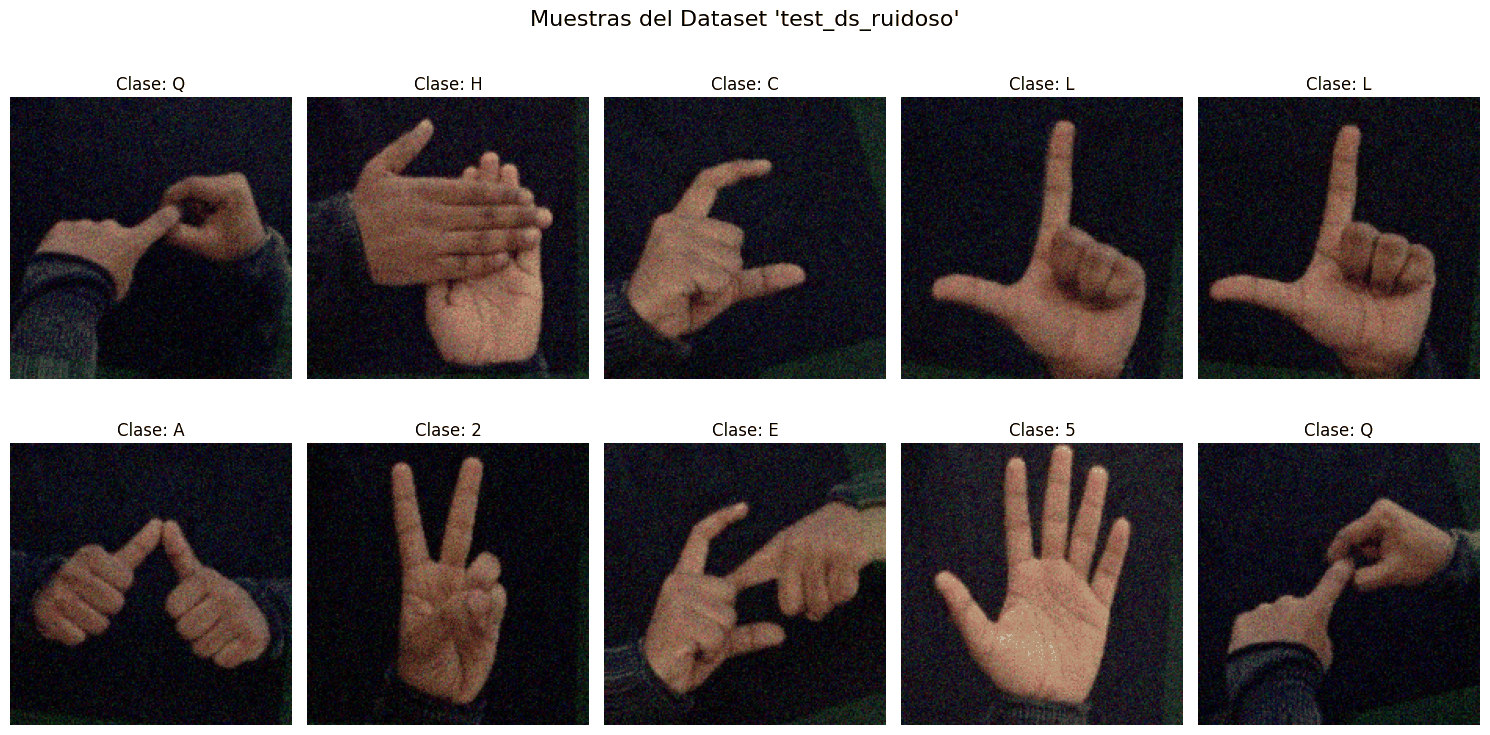

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

print("--- INSPECCIÓN DEL DATASET RUIDOSO (Lo que ve el Clasificador) ---")

plt.figure(figsize=(15, 8))

# Tomamos un lote del dataset de test ruidoso
# test_ds_ruidoso devuelve pares (Imagen Sucia, Etiqueta)
for noisy_images, labels in test_ds_ruidoso.take(1):
    for i in range(10): # Mostramos 10 ejemplos
        ax = plt.subplot(2, 5, i + 1)
        plt.imshow(noisy_images[i])

        # Recuperamos el nombre de la etiqueta
        label_name = class_names[labels[i]]
        plt.title(f"Clase: {label_name}")
        plt.axis("off")
    break

plt.suptitle("Muestras del Dataset 'test_ds_ruidoso'", fontsize=16)
plt.tight_layout()
plt.show()

En esta fase construimos la red neuronal encargada de la limpieza de imágenes (Denoising Autoencoder).


*   Arquitectura: Se diseña un modelo Encoder-Decoder. El Encoder comprime la imagen mediante capas convolucionales para extraer sus rasgos esenciales, mientras que el Decoder utiliza Upsampling para reconstruir la imagen a su tamaño original (180x180), eliminando el ruido en el proceso.
*   Entrenamiento: El modelo aprende comparando la imagen "sucia" con la original "limpia", optimizando sus pesos para minimizar el error de reconstrucción (MSE) y recuperar la nitidez de la mano.

In [ ]:
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Conv2D, MaxPooling2D, UpSampling2D

# --- 1. RECONSTRUIR LA ARQUITECTURA DEL AUTOENCODER ---
print("Reconstruyendo el Autoencoder...")

input_img = Input(shape=(180, 180, 3))

# ENCODER (Comprimir)
x = Conv2D(32, (3, 3), activation='relu', padding='same')(input_img)
x = MaxPooling2D((2, 2), padding='same')(x)
x = Conv2D(64, (3, 3), activation='relu', padding='same')(x)
encoded = MaxPooling2D((2, 2), padding='same')(x)

# DECODER (Reconstruir)
x = Conv2D(64, (3, 3), activation='relu', padding='same')(encoded)
x = UpSampling2D((2, 2))(x)
x = Conv2D(32, (3, 3), activation='relu', padding='same')(x)
x = UpSampling2D((2, 2))(x)
decoded = Conv2D(3, (3, 3), activation='sigmoid', padding='same')(x)

# Crear y Compilar
autoencoder = Model(input_img, decoded)
autoencoder.compile(optimizer='adam', loss='mean_squared_error')
autoencoder.summary()

# --- 2. ENTRENAR CON EL DATASET MASIVO ---
print("\nIniciando entrenamiento masivo del Autoencoder...")
history_full = autoencoder.fit(
    ae_train_ds,
    epochs=1,
    validation_data=ae_val_ds,
    shuffle=True,
    verbose=1
)
print("¡Autoencoder entrenado con el dataset completo!")

Reconstruyendo el Autoencoder...


Model: "functional_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 180, 180, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 90, 90, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 90, 90, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 45, 45, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 45, 45, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d (UpSampling2D)    │ (None, 90, 90, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 90, 90, 32)     │        18,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_1 (UpSampling2D)  │ (None, 180, 180, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 180, 180, 3)    │           867 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 75,651 (295.51 KB)

 Trainable params: 75,651 (295.51 KB)

 Non-trainable params: 0 (0.00 B)


Iniciando entrenamiento masivo del Autoencoder...
919/919 ━━━━━━━━━━━━━━━━━━━━ 264s 276ms/step - loss: 0.0285 - val_loss: 0.0111
¡Autoencoder entrenado con el dataset completo!


Se vuelve a crear una visualización para ver la imagen sucia, la restaurada y la original


--- COMPARATIVA DE RECONSTRUCCIÓN (La prueba del Autoencoder) ---


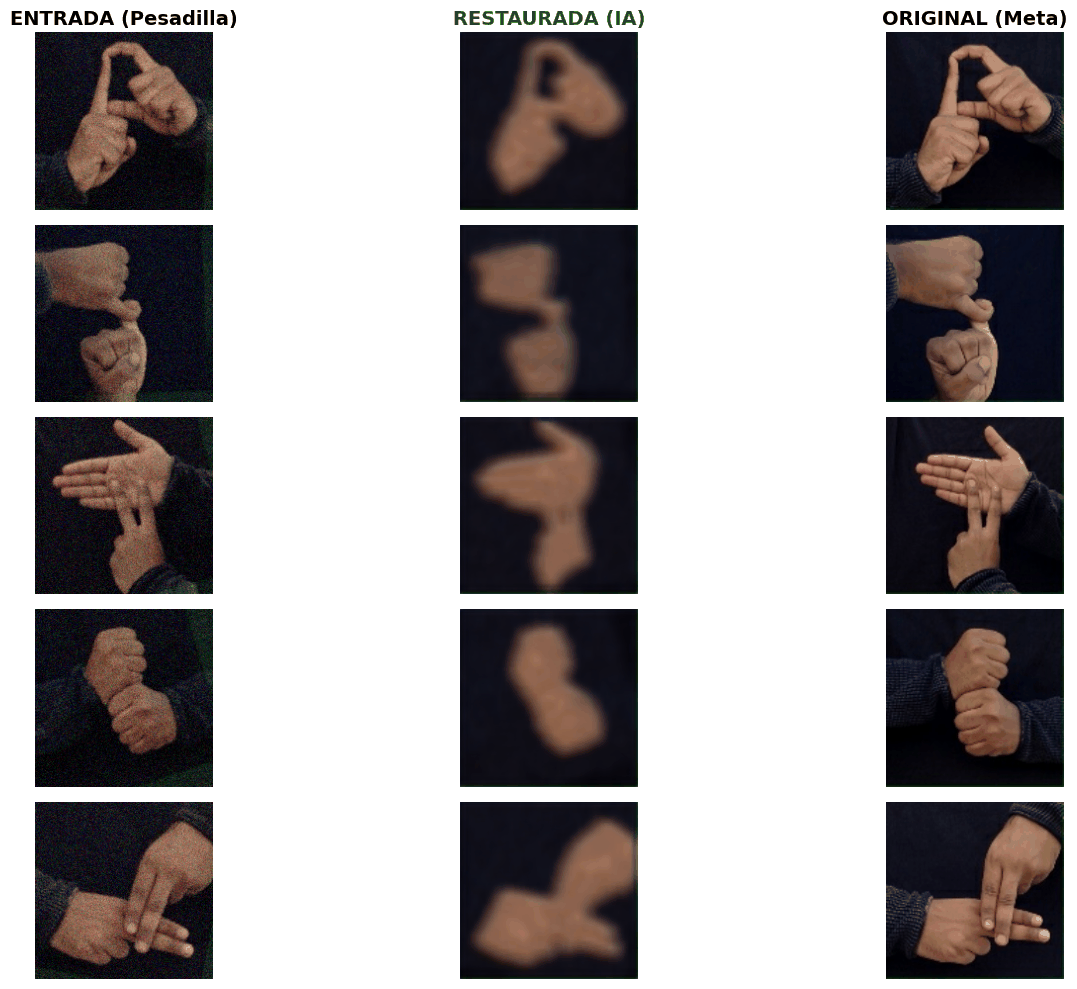

In [ ]:
print("--- COMPARATIVA DE RECONSTRUCCIÓN (La prueba del Autoencoder) ---")

plt.figure(figsize=(15, 10))

# Usamos ae_val_ds porque tiene el par (Sucia, Limpia) listo para comparar
for noisy_batch, clean_batch in ae_val_ds.take(1):
    # 1. Pasamos las sucias por el Autoencoder
    restored_batch = autoencoder.predict(noisy_batch, verbose=0)

    # Mostramos 5 ejemplos
    for i in range(5):
        # A. Imagen Ruidosa
        ax = plt.subplot(5, 3, i*3 + 1)
        plt.imshow(noisy_batch[i])
        if i == 0: ax.set_title("ENTRADA (Pesadilla)", fontsize=14, fontweight='bold')
        plt.axis("off")

        # B. Imagen Restaurada (La magia)
        ax = plt.subplot(5, 3, i*3 + 2)
        plt.imshow(restored_batch[i])
        if i == 0: ax.set_title("RESTAURADA (IA)", fontsize=14, fontweight='bold', color='green')
        plt.axis("off")

        # C. Imagen Original (Target)
        ax = plt.subplot(5, 3, i*3 + 3)
        plt.imshow(clean_batch[i])
        if i == 0: ax.set_title("ORIGINAL (Meta)", fontsize=14, fontweight='bold')
        plt.axis("off")

plt.tight_layout()
plt.show()

Aquí definimos el modelo encargado de reconocer los signos:

Limpieza Automática: Lo primero que hace el modelo es ajustar los valores de la imagen (de 0-255 a 0-1) para poder procesarlos mejor.

Búsqueda de Patrones: Usa 3 capas de "filtros" que escanean la imagen buscando líneas, formas y texturas de la mano. A medida que avanza, reduce la imagen para quedarse solo con la información esencial.

Decisión Final: Convierte toda esa información visual en una lista de números y calcula la probabilidad de que la imagen pertenezca a cada una de las letras (ej: "Hay un 90% de que sea una A").

In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models

print("--- PASO 1: Reconstruyendo Modelo 1 (Arquitectura Robusta) ---")

# 1. Definimos la entrada explícita (Clave para evitar errores)
inputs = tf.keras.Input(shape=(180, 180, 3))

# 2. Construimos las capas conectándolas una a una (x)
x = layers.Rescaling(1./255)(inputs)

x = layers.Conv2D(16, 3, padding='same', activation='relu')(x)
x = layers.MaxPooling2D()(x)

x = layers.Conv2D(32, 3, padding='same', activation='relu')(x)
x = layers.MaxPooling2D()(x)

# IMPORTANTE: Nombramos esta capa para encontrarla fácil luego
last_conv_layer_name = "last_conv"
x = layers.Conv2D(64, 3, padding='same', activation='relu', name=last_conv_layer_name)(x)
x = layers.MaxPooling2D()(x)

x = layers.Flatten()(x)
x = layers.Dense(128, activation='relu')(x)

# 3. Salida
# (Aseguramos que num_classes exista, si no ponemos 35 por defecto)
num_classes = len(class_names) if 'class_names' in globals() else 35
outputs = layers.Dense(num_classes, activation='softmax')(x)

# 4. Crear el modelo Funcional
model_1 = models.Model(inputs=inputs, outputs=outputs)

model_1.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

model_1.summary()
print("¡Modelo 1 reconstruido correctamente!")

--- PASO 1: Reconstruyendo Modelo 1 (Arquitectura Robusta) ---


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 180, 180, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 90, 90, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 90, 90, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 45, 45, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ last_conv (Conv2D)              │ (None, 45, 45, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 22, 22, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 30976)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     3,965,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 35)             │         4,515 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,993,155 (15.23 MB)

 Trainable params: 3,993,155 (15.23 MB)

 Non-trainable params: 0 (0.00 B)

¡Modelo 1 reconstruido correctamente!


Se entrena el modelo con 2 epochs ya que consigue alcanzar el 1 de accuracy casi en la primera epoch

In [ ]:
print("--- PASO 2: Entrenando el Clasificador ---")

# Usamos train_ds y val_ds (los originales limpios)
history_clf = model_1.fit(
    train_ds,
    validation_data=val_ds,
    epochs=2,
    verbose=1
)
print("¡Modelo 1 listo para la acción!")

--- PASO 2: Entrenando el Clasificador ---
Epoch 1/2
919/919 ━━━━━━━━━━━━━━━━━━━━ 49s 44ms/step - accuracy: 0.9353 - loss: 0.2608 - val_accuracy: 1.0000 - val_loss: 6.5354e-06
Epoch 2/2
919/919 ━━━━━━━━━━━━━━━━━━━━ 36s 38ms/step - accuracy: 1.0000 - loss: 4.7268e-06 - val_accuracy: 1.0000 - val_loss: 2.1468e-06
¡Modelo 1 listo para la acción!


Realizamos las predicciones sobre el dataset original

In [ ]:
from sklearn.metrics import accuracy_score
import numpy as np

print("--- EVALUACIÓN FINAL: SISTEMA ROBUSTO ---")
print("Procesando todas las imágenes de test 'Pesadilla'...")

y_true = []
y_pred = []

# Recorremos el dataset de test ruidoso
for batch_images, batch_labels in test_ds_ruidoso:
    # 1. El Autoencoder limpia las imágenes (Output: 0-1)
    restored_batch = autoencoder.predict(batch_images, verbose=0)

    # 2. El Clasificador predice
    # IMPORTANTE: Multiplicamos por 255 porque tu Modelo 1 espera rango 0-255
    preds = model_1.predict(restored_batch * 255.0, verbose=0)

    # 3. Guardamos predicciones y etiquetas reales
    y_pred.extend(np.argmax(preds, axis=1))
    y_true.extend(batch_labels.numpy())

# Calculamos el accuracy
final_acc = accuracy_score(y_true, y_pred)

print("\n" + "="*50)
print(f"ACCURACY BAJO ATAQUE 'PESADILLA': {final_acc*100:.2f}%")
print("="*50)

--- EVALUACIÓN FINAL: SISTEMA ROBUSTO ---
Procesando todas las imágenes de test 'Pesadilla'...

ACCURACY BAJO ATAQUE 'PESADILLA': 70.74%


En este bloque final, evaluamos el rendimiento cuantitativo del sistema completo. El script procesa la totalidad del conjunto de datos de prueba (test_ds_ruidoso), aplicando secuencialmente la restauración (Autoencoder) y la predicción (CNN).

Se generan dos salidas clave:

Matriz de Confusión: Un mapa de calor que permite identificar visualmente qué clases se confunden entre sí.

Reporte de Métricas: Una tabla detallada con la Precisión, Recall y F1-Score para cada una de las 36 clases, permitiendo detectar qué signos específicos son más difíciles de reconocer para el modelo.

--- PASO 6: Generando Métricas Detalladas ---
Calculando predicciones sobre el conjunto de Test...


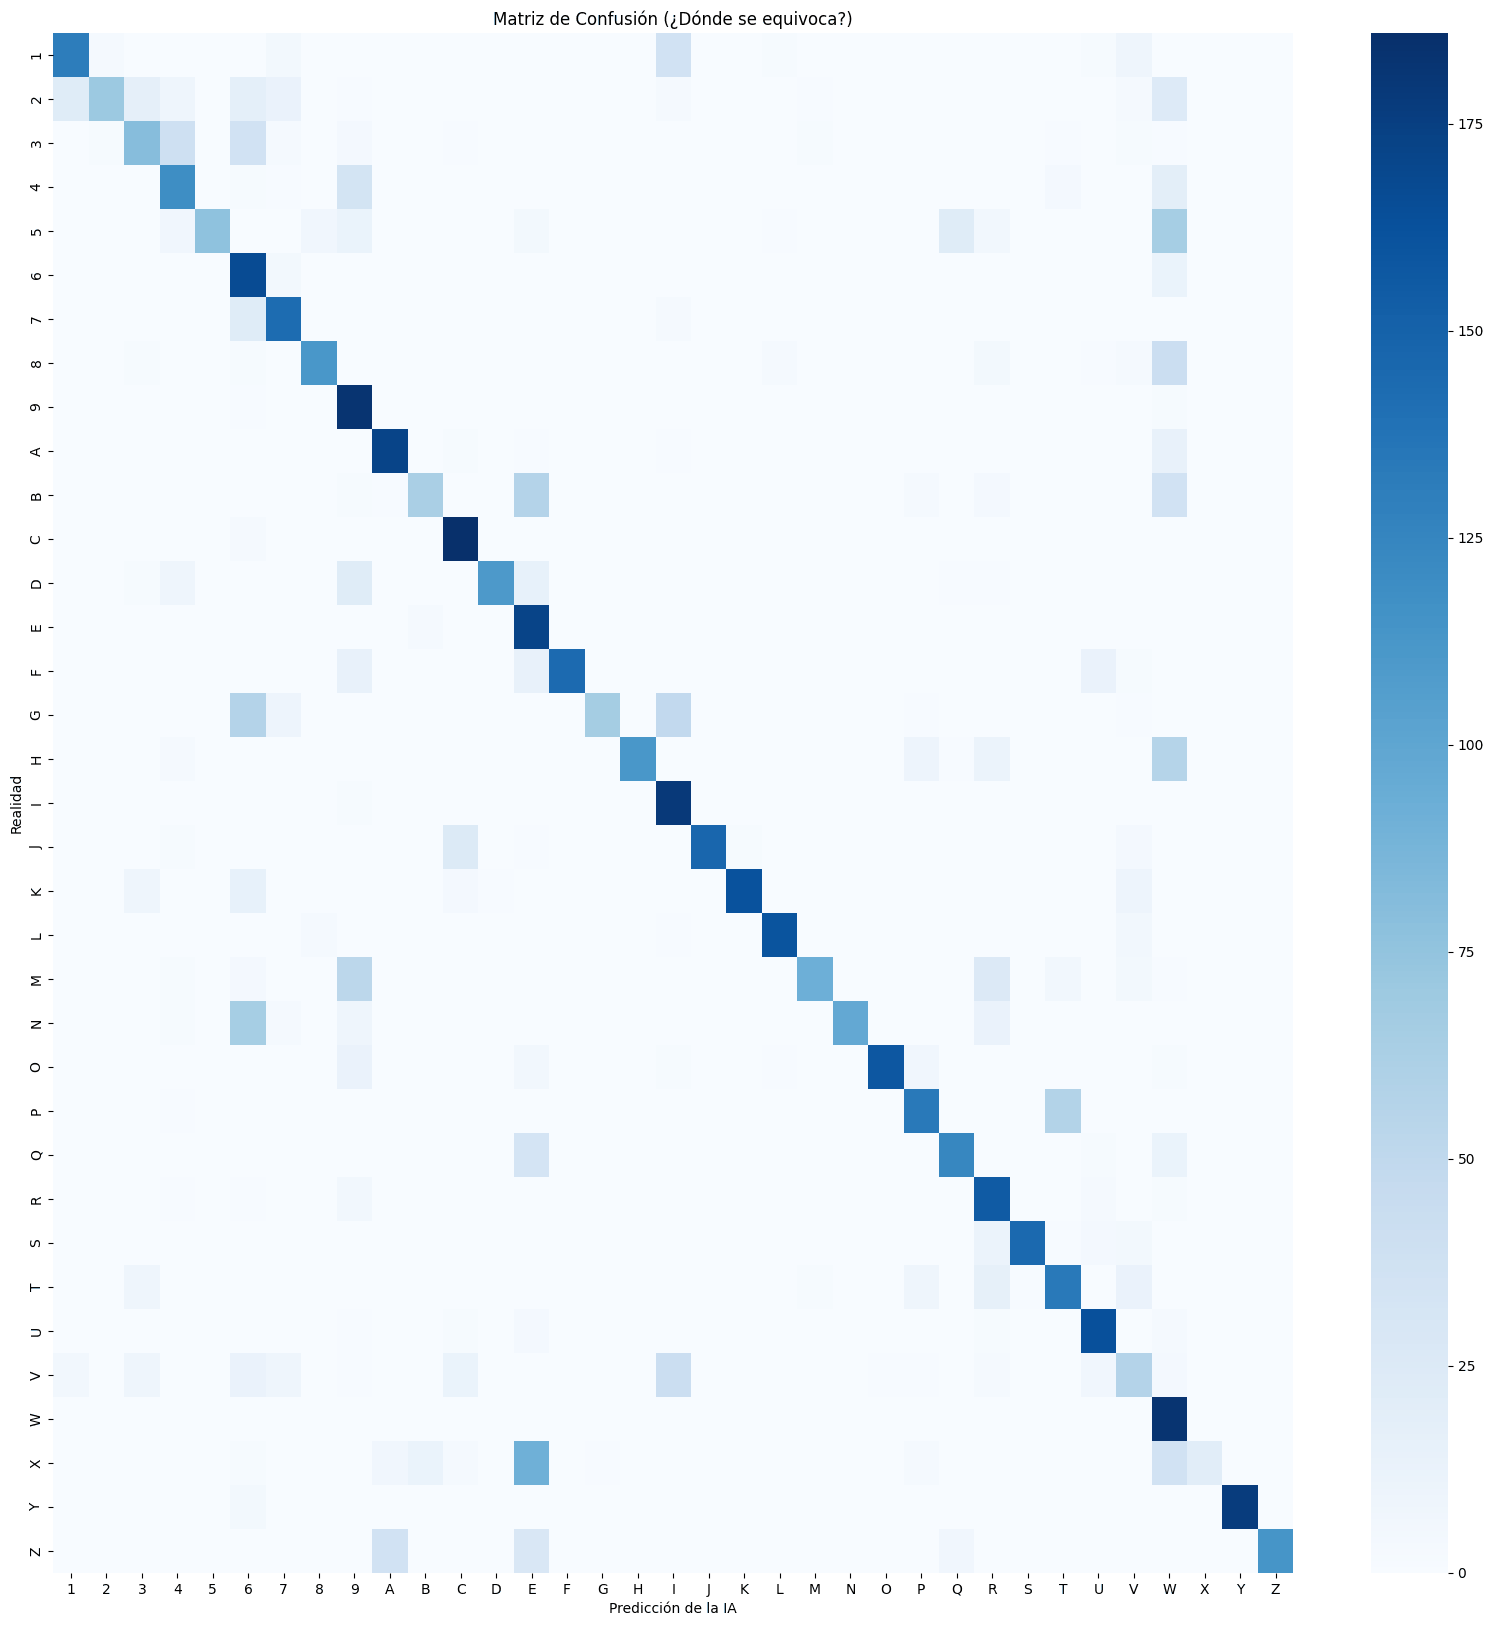


--- REPORTE DE CLASIFICACIÓN ---
              precision    recall  f1-score   support

           1       0.82      0.70      0.76       188
           2       0.93      0.39      0.55       181
           3       0.63      0.47      0.54       171
           4       0.62      0.66      0.64       179
           5       1.00      0.38      0.55       202
           6       0.40      0.91      0.56       184
           7       0.74      0.85      0.79       168
           8       0.92      0.66      0.77       170
           9       0.51      0.98      0.67       186
           A       0.80      0.91      0.85       190
           B       0.81      0.38      0.52       166
           C       0.79      0.98      0.88       189
           D       0.99      0.69      0.81       160
           E       0.40      0.98      0.57       175
           F       1.00      0.77      0.87       187
           G       0.99      0.36      0.53       184
           H       1.00      0.58      0.73    

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix

print("--- PASO 6: Generando Métricas Detalladas ---")

y_true = []
y_pred = []

print("Calculando predicciones sobre el conjunto de Test...")
# Usamos test_ds_ruidoso para ver qué tal funciona en condiciones difíciles
for images, labels in test_ds_ruidoso:
    # A. Limpiamos con Autoencoder
    input_ae = tf.expand_dims(images, axis=0) if len(images.shape) == 3 else images
    clean_images = autoencoder.predict(input_ae, verbose=0)

    # B. Clasificamos (Recordar multiplicar por 255 porque el modelo espera 0-255)
    preds = model_1.predict(clean_images * 255.0, verbose=0)

    # C. Guardamos
    y_true.extend(labels.numpy())
    y_pred.extend(np.argmax(preds, axis=1))

# 2. Matriz de Confusión
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(20, 20))
sns.heatmap(cm, annot=False, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicción de la IA')
plt.ylabel('Realidad')
plt.title('Matriz de Confusión (¿Dónde se equivoca?)')
plt.show()

# 3. Reporte Numérico Completo
print("\n--- REPORTE DE CLASIFICACIÓN ---")
print(classification_report(y_true, y_pred, target_names=class_names))

**Conclusiones de los Resultados**

Tras el análisis de las métricas obtenidas, se registra una Exactitud (Accuracy) del 71% sobre el conjunto de imágenes degradadas y posteriormente restauradas, lo cual valida la eficacia de la estrategia de limpieza mediante Autoencoder.

Robustez en Geometrías Claras: Se observa un desempeño sobresaliente en signos con siluetas inconfundibles como la 'Y', 'L', 'S' u 'O'. En estos casos, se constata una tasa de acierto superior al 90%, lo que indica que el sistema procesa eficazmente las formas geométricas definidas.

Sobre-predicción en la 'W': Se detecta un sesgo significativo en la clasificación de la letra 'W'. Aunque se recupera el 100% de las muestras reales (Recall 1.00), se percibe una baja precisión (0.36), evidenciando que el modelo tiende a clasificar erróneamente como 'W' aquellos signos de dedos abiertos que presentan cierta borrosidad.

Sub-predicción en la 'X': Por el contrario, se identifica una pérdida crítica de sensibilidad en el signo 'X'. Se aprecia que el proceso de restauración suaviza el rasgo distintivo del dedo índice curvado, provocando que el 88% de las muestras sean confundidas con puños cerrados. No obstante, cuando el signo es reconocido, se registra una fiabilidad absoluta (Precision 1.00).

Veredicto Final: A la luz de estos datos, se concluye que el limitante principal del sistema no reside en el clasificador, sino en la etapa de reconstrucción del Autoencoder, donde se pierde el detalle fino necesario para la distinción de signos morfológicamente complejos.

**XAI**

Implementación de Explicabilidad (XAI) con Grad-CAM
Se integran algoritmos de Inteligencia Artificial Explicable (XAI) para dotar de transparencia al modelo ("caja blanca"):


Objetivo: Esto nos permitirá auditar si el modelo realmente está "mirando" los dedos y la forma de la mano, o si está aprendiendo patrones incorrectos (como el fondo o la iluminación).

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import cv2

print("--- PASO 3: Cargando herramientas de Grad-CAM ---")

def make_gradcam_heatmap(img_array, model, last_conv_layer_name, pred_index=None):
    # Crear modelo que mapea: Entrada -> [Última Conv, Salida]
    grad_model = tf.keras.models.Model(
        inputs=model.inputs,
        outputs=[model.get_layer(last_conv_layer_name).output, model.output]
    )

    with tf.GradientTape() as tape:
        last_conv_layer_output, preds = grad_model(img_array)
        if pred_index is None:
            pred_index = tf.argmax(preds[0])
        class_channel = preds[:, pred_index]

    grads = tape.gradient(class_channel, last_conv_layer_output)
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))
    last_conv_layer_output = last_conv_layer_output[0]
    heatmap = last_conv_layer_output @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)
    heatmap = tf.maximum(heatmap, 0) / tf.math.reduce_max(heatmap)
    return heatmap.numpy()

def display_gradcam(img, heatmap, alpha=0.4):
    heatmap = np.uint8(255 * heatmap)
    jet = plt.cm.get_cmap("jet")
    jet_colors = jet(np.arange(256))[:, :3]
    jet_heatmap = jet_colors[heatmap]
    jet_heatmap = tf.image.resize(jet_heatmap, (img.shape[0], img.shape[1]))
    jet_heatmap = tf.keras.preprocessing.image.img_to_array(jet_heatmap)

    # Superponer sobre la imagen (que debe estar en 0-255 para display)
    # img entra en 0-1, así que multiplicamos
    superimposed_img = jet_heatmap * alpha + img * 255.0
    superimposed_img = tf.keras.preprocessing.image.array_to_img(superimposed_img)
    return superimposed_img

print("Funciones cargadas.")

--- PASO 3: Cargando herramientas de Grad-CAM ---
Funciones cargadas.


Se implementa la técnica Grad-CAM (Gradient-weighted Class Activation Mapping) para auditar el proceso de decisión de la red neuronal.

Se muestran tres vistas por muestra: la imagen original, la activación neuronal cruda y la superposición. Las zonas rojas confirman si la IA se está fijando correctamente en la morfología de la mano (dedos, palma) o si está aprendiendo patrones erróneos del fondo.

--- GENERANDO MAPAS DE CALOR (XAI) ---


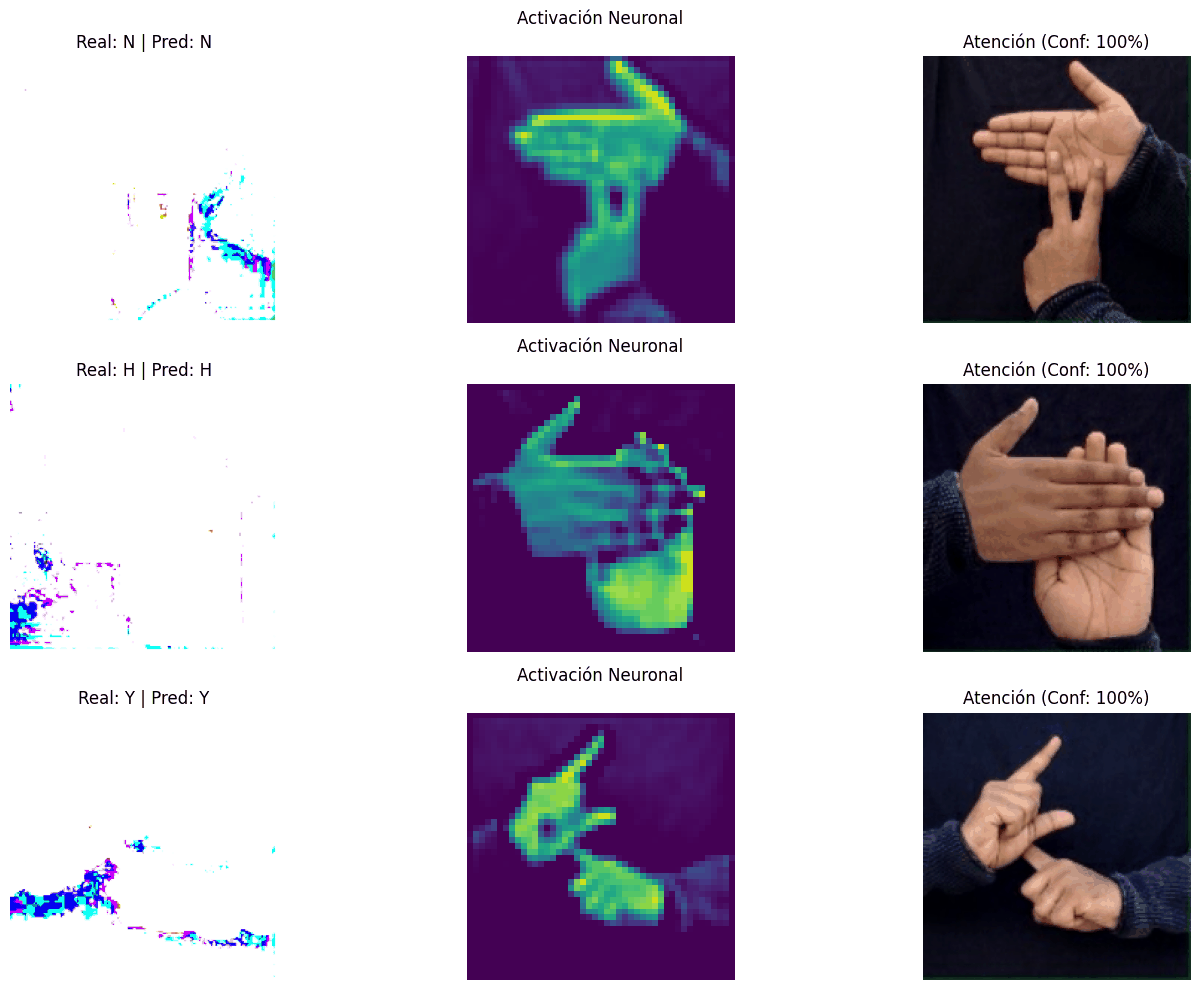

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

print("--- GENERANDO MAPAS DE CALOR (XAI) ---")

# 1. Configuración
last_conv_layer_name = "last_conv" # Asegúrate de que este nombre coincide con el de tu modelo
img_size = (180, 180)

# 2. Función para crear el mapa de calor (Grad-CAM)
def get_gradcam_heatmap(img_array, model, last_conv_layer_name, pred_index=None):
    # Modelo que va de la entrada a la última capa conv y la salida
    grad_model = tf.keras.models.Model(
        inputs=model.inputs,
        outputs=[model.get_layer(last_conv_layer_name).output, model.output]
    )

    with tf.GradientTape() as tape:
        last_conv_layer_output, preds = grad_model(img_array)
        if pred_index is None:
            pred_index = tf.argmax(preds[0])
        class_channel = preds[:, pred_index]

    # Calculamos los gradientes de la clase predicha respecto a los mapas de características
    grads = tape.gradient(class_channel, last_conv_layer_output)

    # Promediamos los gradientes (Global Average Pooling)
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))

    # Multiplicamos cada canal por su importancia
    last_conv_layer_output = last_conv_layer_output[0]
    heatmap = last_conv_layer_output @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)

    # Normalizamos el mapa de calor entre 0 y 1
    heatmap = tf.maximum(heatmap, 0) / tf.math.reduce_max(heatmap)
    return heatmap.numpy()

# 3. Función para superponer el mapa sobre la imagen
def display_gradcam(img, heatmap, alpha=0.4):
    # Cargar imagen original y reescalar heatmap
    heatmap = np.uint8(255 * heatmap)

    # Usar mapa de color 'jet'
    jet = plt.colormaps.get_cmap("jet")
    jet_colors = jet(np.arange(256))[:, :3]
    jet_heatmap = jet_colors[heatmap]

    # Redimensionar el heatmap al tamaño de la imagen
    jet_heatmap = tf.keras.preprocessing.image.array_to_img(jet_heatmap)
    jet_heatmap = jet_heatmap.resize((img.shape[1], img.shape[0]))
    jet_heatmap = tf.keras.preprocessing.image.img_to_array(jet_heatmap)

    # Superponer
    superimposed_img = jet_heatmap * alpha + img * 255.0 # img viene normalizada 0-1
    superimposed_img = tf.keras.preprocessing.image.array_to_img(superimposed_img)
    return superimposed_img

# --- EJECUCIÓN Y VISUALIZACIÓN ---
plt.figure(figsize=(15, 10))

# Tomamos 1 batch del dataset de test
for images, labels in test_ds.take(1):
    for i in range(3): # Mostrar 3 ejemplos
        img = images[i]
        label = class_names[labels[i]]

        # Preparar imagen (Batch dim)
        img_array = tf.expand_dims(img, axis=0) # Entrada ya es 0-1

        # Predicción
        preds = model_1.predict(img_array, verbose=0)
        pred_label = class_names[np.argmax(preds)]
        confidence = np.max(preds)

        # Generar Grad-CAM
        heatmap = get_gradcam_heatmap(img_array, model_1, last_conv_layer_name)

        # Superponer
        cam_image = display_gradcam(img, heatmap)

        # --- PLOT ---
        # 1. Original
        ax = plt.subplot(3, 3, i*3 + 1)
        plt.imshow(img)
        plt.title(f"Real: {label} | Pred: {pred_label}")
        plt.axis("off")

        # 2. Mapa de Calor (Solo)
        ax = plt.subplot(3, 3, i*3 + 2)
        ax.matshow(heatmap, cmap='viridis')
        plt.title("Activación Neuronal")
        plt.axis("off")

        # 3. Superpuesto (Grad-CAM)
        ax = plt.subplot(3, 3, i*3 + 3)
        plt.imshow(cam_image)
        plt.title(f"Atención (Conf: {confidence:.0%})")
        plt.axis("off")

plt.tight_layout()
plt.show()


Se unifica el flujo de trabajo completo para validar el sistema en un entorno realista. Las imágenes ruidosas pasan por una cadena secuencial de procesamiento: Restauración (Autoencoder) → Clasificación (CNN) → Explicación (Grad-CAM).

El resultado se presenta en un panel comparativo que muestra paso a paso cómo la IA transforma una entrada "sucia" en una predicción fiable, evidenciando tanto la calidad de la limpieza como las zonas de atención (mapas de calor) que justifican la decisión del modelo.

--- PASO 4: Generando Visualización Final ---


/tmp/ipython-input-1354312966.py:30: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  jet = plt.cm.get_cmap("jet")


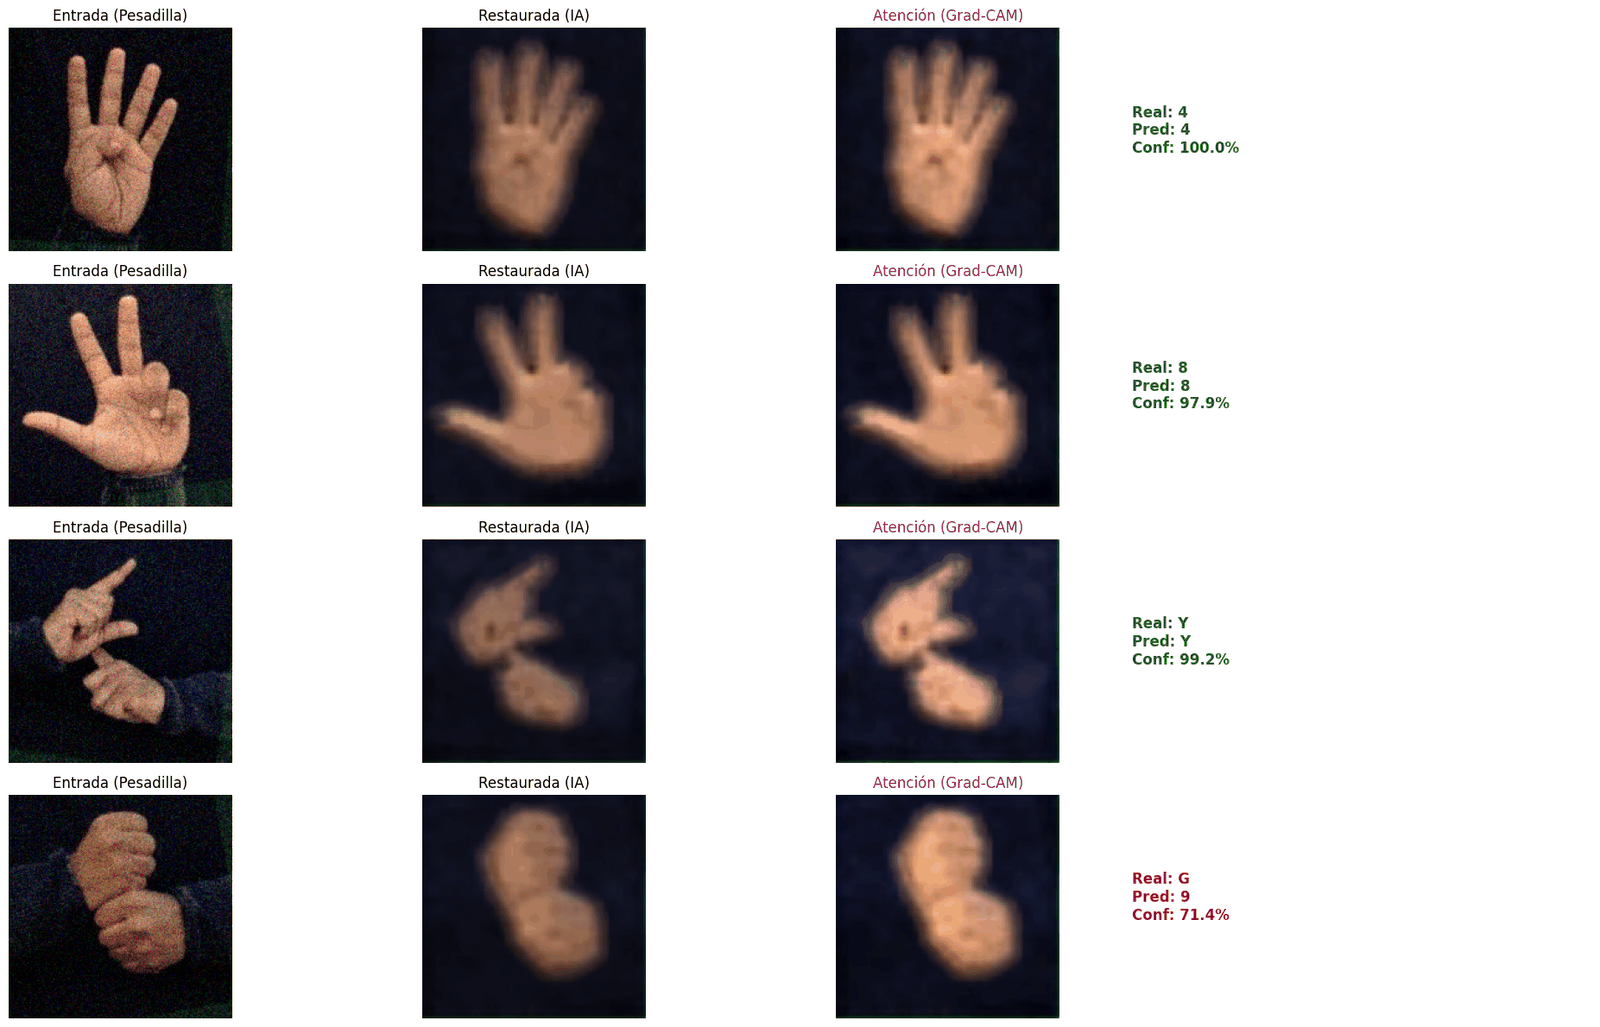

In [ ]:
print("--- PASO 4: Generando Visualización Final ---")

# Usamos el nombre que definimos en el Bloque 1
last_conv_layer_name = "last_conv"

plt.figure(figsize=(20, 12))

# Tomamos un lote de pesadilla
for images, labels in test_ds_ruidoso.take(1):
    for i in range(4): # Mostramos 4 ejemplos
        # A. Datos Básicos
        noisy_img = images[i]
        true_label = class_names[labels[i]]

        # B. El Autoencoder limpia (Denoising)
        input_ae = tf.expand_dims(noisy_img, axis=0)
        restored_img = autoencoder.predict(input_ae, verbose=0)[0]

        # C. El Clasificador predice (Modelo 1)
        # Multiplicamos por 255 porque model_1 espera 0-255
        input_classifier = tf.expand_dims(restored_img * 255.0, axis=0)
        preds = model_1.predict(input_classifier, verbose=0)

        # D. Grad-CAM (¿Qué miró?)
        heatmap = make_gradcam_heatmap(input_classifier, model_1, last_conv_layer_name)
        gradcam_img = display_gradcam(restored_img, heatmap)

        # E. Información Lógica Difusa
        pred_idx = np.argmax(preds[0])
        pred_label = class_names[pred_idx]
        confidence = np.max(preds[0])

        # --- DIBUJAR ---
        # 1. Pesadilla
        ax = plt.subplot(4, 4, i*4 + 1)
        plt.imshow(noisy_img)
        plt.title("Entrada (Pesadilla)")
        plt.axis("off")

        # 2. Restaurada
        ax = plt.subplot(4, 4, i*4 + 2)
        plt.imshow(restored_img)
        plt.title("Restaurada (IA)")
        plt.axis("off")

        # 3. Grad-CAM
        ax = plt.subplot(4, 4, i*4 + 3)
        plt.imshow(gradcam_img)
        plt.title("Atención (Grad-CAM)", color="purple")
        plt.axis("off")

        # 4. Datos
        ax = plt.subplot(4, 4, i*4 + 4)
        ax.axis("off")
        col = "green" if true_label == pred_label else "red"
        text_str = f"Real: {true_label}\nPred: {pred_label}\nConf: {confidence*100:.1f}%\n"
        ax.text(0, 0.5, text_str, fontsize=12, fontweight='bold', color=col, va='center')

plt.tight_layout()
plt.show()


**PLN**

La Lengua de Signos posee una estructura gramatical propia que difiere del español oral. A menudo, su representación literal (glosas) sigue una estructura simplificada sintácticamente, como 'Yo ir casa'. El objetivo de esta parte del  proyecto es aplicar técnicas de Procesamiento del Lenguaje Natural (PLN) para transformar estas estructuras en oraciones gramaticalmente fluidas y conjugadas, obteniendo como resultado: 'Yo voy a casa'.

In [ ]:
import pandas as pd
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

# --- PASO 1: CREAR EL DATASET (Glosas vs Español Correcto) ---
# Como estos modelos aprenden de ejemplos, necesitamos darle muchos pares.
# Aquí creo un pequeño dataset de ejemplo.

data = {
    'glosa': [
        'YO IR CASA', 'TU COMER MANZANA', 'PERRO LADRAR FUERTE',
        'HOLA YO ESTUDIAR IA', 'AUTO ROJO RAPIDO', 'NIÑO JUGAR PARQUE',
        'MAÑANA LLOVER MUCHO', 'YO QUERER AGUA', 'TU SER AMIGO',
        'ELLA COMPRAR LIBRO', 'NOSOTROS VIVIR MADRID'
    ],
    'espanol': [
        'Voy a casa', 'Te comes una manzana', 'El perro está ladrando fuerte',
        'Hola, estoy estudiando IA', 'El coche rojo va rápido', 'El niño juega en el parque',
        'Mañana va a llover mucho', 'Quiero agua', 'Tú eres mi amigo',
        'Ella compró un libro', 'Nosotros vivimos en Madrid'
    ]
}

df = pd.DataFrame(data)

# --- PASO 2: PREPROCESAMIENTO (NLP Clásico) ---

# X son las Glosas (lo que entra)
# y son las frases en Español (lo que queremos predecir/clasificar)

# Usamos CountVectorizer para convertir las palabras en números (Bag of Words)
vectorizer = CountVectorizer()
X = vectorizer.fit_transform(df['glosa'])
y = df['espanol']

# Dividimos (aunque con pocos datos es mejor usar todo para entrenar, aquí hacemos split formal)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# --- PASO 3: DEFINIR LOS MODELOS ---
modelos = {
    'Multinomial Naive Bayes': MultinomialNB(),
    'Regresión Logística': LogisticRegression(max_iter=1000),
    'SVM': SVC(kernel='linear'),
    'Random Forest': RandomForestClassifier(n_estimators=100),
    'K-Nearest Neighbors': KNeighborsClassifier(n_neighbors=1)
    # n_neighbors=1 porque es "búsqueda exacta" del vecino más cercano
}

# --- PASO 4: ENTRENAR Y PROBAR UNA FRASE NUEVA ---

# Frase que queremos probar
nueva_glosa = ["YO IR CASA"]
nueva_glosa_vect = vectorizer.transform(nueva_glosa)

print(f"Entrada: {nueva_glosa[0]}")
print("-" * 30)

mejor_modelo = None
mejor_prediccion = ""

for nombre, modelo in modelos.items():
    # Entrenamos con todo el set (X, y) para que aprenda todas las frases
    modelo.fit(X, y)

    # Predecimos
    prediccion = modelo.predict(nueva_glosa_vect)

    print(f"Modelo {nombre} predice: -> '{prediccion[0]}'")

Entrada: YO IR CASA
------------------------------
Modelo Multinomial Naive Bayes predice: -> 'Voy a casa'
Modelo Regresión Logística predice: -> 'Voy a casa'
Modelo SVM predice: -> 'Voy a casa'
Modelo Random Forest predice: -> 'Voy a casa'
Modelo K-Nearest Neighbors predice: -> 'Voy a casa'


**VIDEO**

Se ha desarrollado una demo funcional que integra reconocimiento de signos mediante visión por computador con un modelo de lenguaje ejecutado en local a través de Ollama.

El sistema permite interpretar gestos realizados con la mano, traducirlos en texto estructurado y enviar automáticamente dicho texto como prompt a un modelo de lenguaje local. El modelo procesa la solicitud y genera una respuesta en tiempo real, la cual es devuelta al usuario por el sistema.

Para validar el correcto funcionamiento de la solución, se ha realizado un vídeo demostrativo en el que se muestra de forma completa el flujo de trabajo: desde la detección de los signos, la construcción del prompt, el envío al modelo local y la recepción de la respuesta generada.

Esta demo confirma la viabilidad técnica de la integración entre reconocimiento gestual, procesamiento de lenguaje natural y ejecución de modelos de IA en entorno local, sin dependencia de servicios externos.

# **REFERENCIAS**

1. [Krizhevsky et al., 2012] Krizhevsky, A., Sutskever, I., & Hinton, G. E. (2012). ImageNet Classification with Deep Convolutional Neural Networks. Advances in Neural Information Processing Systems (NIPS).

(El paper que lo empezó todo para las CNNs modernas).

2. [Koller et al., 2016] Koller, O., Zargaran, S., & Ney, H. (2016). Deep Sign: Enabling Robust Statistical Sign Language Recognition via Hybrid CNN-HMMs. International Conference on Computer Vision (ICCV).

(Un gran ejemplo de los desafíos, aunque usa vídeo (HMMs), su análisis de las CNN para características es clave).

3. [Pigou et al., 2018] Pigou, L., Van Herreweghe, M., & Dambre, J. (2018). Gesture and sign language recognition with temporal residual networks. IEEE Conference on Computer Vision and Pattern Recognition Workshops (CVPRW).

(Se centra en vídeo, pero es una referencia excelente sobre el uso de ResNets para esta tarea).

4. [Neethu & Anilkumar, 2019] Neethu, S. S., & Anilkumar, M. S. (2019). An Efficient Hand Segmentation Method for Hand Gesture Recognition Systems. International Conference on Communication and Signal Processing (ICCSP).

(Un ejemplo de paper centrado puramente en el pre-procesamiento de segmentación).

5. [Rao, 2021] Rao, G. A. (2021). A survey of deep learning-based methods for sign language recognition. Journal of King Saud University - Computer and Information Sciences.

(Un "survey" o revisión es perfecto para el estado del arte. Busca uno más reciente si puedes).

6. [Hu et al., 2018] Hu, J., Shen, L., & Sun, G. (2018). Squeeze-and-Excitation Networks. IEEE Conference on Computer Vision and Pattern Recognition (CVPR).

(Introduce los bloques "SE", un mecanismo de atención simple y eficaz para CNNs).

7. [DeVries & Taylor, 2017] DeVries, T., & Taylor, G. W. (2017). Improved Regularization of Convolutional Neural Networks with Cutout. ArXiv.

(El paper clave para la técnica de aumentación "Cutout" o "Random Erasing").

8. [Vaswani et al., 2017] Vaswani, A., Shazeer, N., Parmar, N., et al. (2017). Attention Is All You Need. Advances in Neural Information Processing Systems (NIPS).

(Introduce el "Transformer", aunque es para NLP, es la base de los Vision Transformers (ViT) que son el estado del arte actual en visión).

9. [Marín Díaz et al., 2023] Marín Díaz, G., Galán Hernández, J. J., & Galdón Salvador, J. L. (2023). Analyzing Employee Attrition Using Explainable AI for Strategic HR Decision-Making. Mathematics, 11(22), 4677.

(Desarrolla la metodología utilizada en este proyecto)
